# M5.S1 Hybrid computing patterns

We will build a heat simulation one step at a time. You will log in to the cluster, create the files, compile the program, request resources through Slurm and check the results. We keep the calculation the same while changing how it runs.

Start with the heat equation and the SSH exercises below. Read the explanations here and type or paste the shell commands into your SSH terminal. Complete the CPU exercises before trying the GPU and profiling extensions.

Later in the notebook, you can run a guided MPI/OpenMP example and a short CUDA vector-add experiment. The final section, “Run the complete heat experiment”, creates the heat-solver files and submits the experiments from Jupyter. Use that section if you want to check the full workflow without typing every command first.

Keep your predictions, job IDs, compiler flags and measurements in your notes. Use the saved fields and logs to explain the results.

Run the sections you need rather than using Run All. The guided example submits a GPU job when `RUN_GPU=True`, its default setting. The complete heat experiment has separate CPU and GPU submission switches, both initially `False`.

## 1. What are we solving?

Imagine a thin metal plate. We hold its top edge at 100 °C and its other edges at 0 °C. Initially the interior is cold. We want to calculate how temperature spreads into the plate.

A solver is the program that approximates the mathematical equation. It stores a grid of temperatures and calculates the next grid from the current one. This is a simplified teaching model: constant diffusivity, no internal heat sources, no varying material properties.

For temperature $T(x,y,t)$, the two-dimensional heat equation is

$$\frac{\partial T}{\partial t}=\alpha\left(\frac{\partial^2T}{\partial x^2}+\frac{\partial^2T}{\partial y^2}\right).$$

Here $\alpha$ is thermal diffusivity. A forward time step and centred spatial differences give

$$T^{k+1}_{y,x}=T^k_{y,x}+r_x(T^k_{y,x-1}-2T^k_{y,x}+T^k_{y,x+1})+r_y(T^k_{y-1,x}-2T^k_{y,x}+T^k_{y+1,x}),$$

where $r_x=\alpha\Delta t/\Delta x^2$ and $r_y=\alpha\Delta t/\Delta y^2$. For this explicit scheme, use $r_x+r_y\leq 1/2$. We use dimensionless $\Delta x=\Delta y=1$, $\alpha=1$ and $\Delta t=1/4$, exactly at that bound. Thus

$$\boxed{T^{k+1}_{y,x}=\tfrac14(T^k_{y-1,x}+T^k_{y+1,x}+T^k_{y,x-1}+T^k_{y,x+1})}.$$

This is the four-neighbour update we will implement. Do not change the coefficient casually. A larger value can make this explicit method unstable. The number of steps is fixed: we are observing transient diffusion, not stopping on a steady-state residual.

Implementation choices

- `N` includes boundary cells. `old[y*N+x]` is a row-major, contiguous array element.
- We read `old` and write `next`. Reading partly updated neighbours would implement a different algorithm.
- We keep boundaries fixed. The top row, including its two corners, is 100 °C. The remaining side and bottom boundary cells are 0 °C. This corner convention is deliberate and identical in every version.
- Increasing `N` here increases the size of the dimensionless grid. We do not claim to refine a fixed physical plate. For that experiment you would also change spacing and the stable time step.

Write down your prediction. After the first update, what is the temperature of a non-corner cell immediately below the hot edge? It has one 100 °C neighbour and three 0 °C neighbours: 25 °C. The cell two rows below remains 0 °C at that first update.

### Watch one time step become many

Run this small Python illustration in Jupyter if NumPy/Matplotlib are available. It explains the stencil visually. The C programs below do the actual HPC work. Notice that the heated region expands gradually and that the fixed edge stays at 100 °C.

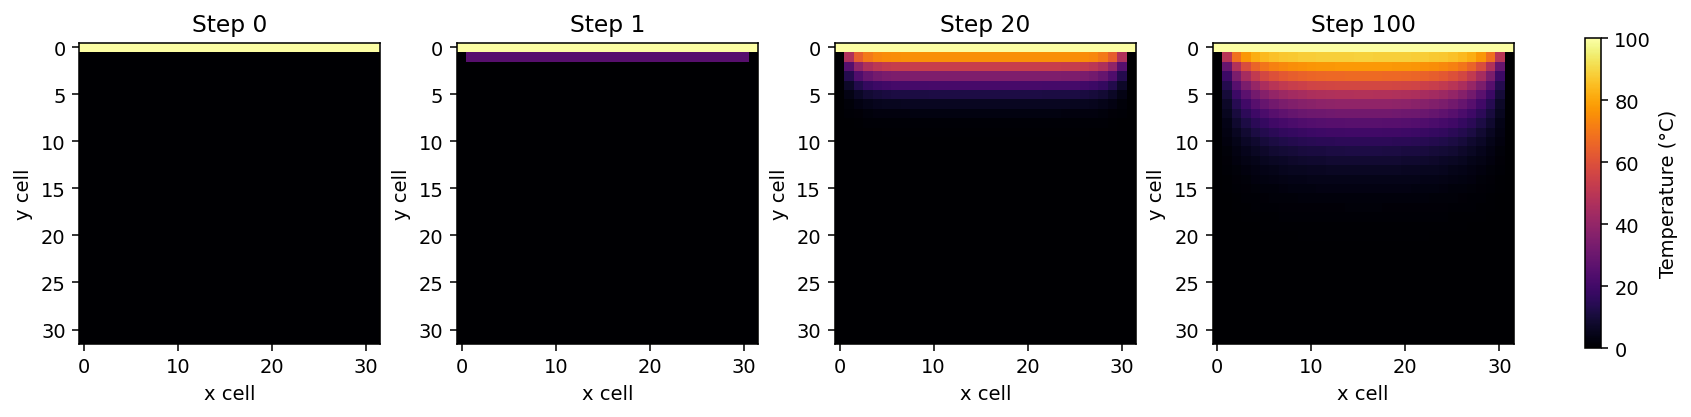

Python stencil illustration. No Slurm job or cluster timing is involved.


In [1]:
# A small Python explanation of the stencil, not an HPC performance measurement.
import numpy as np
import matplotlib.pyplot as plt
n = 32
old = np.zeros((n, n), dtype=np.float64)
old[0, :] = 100.0
snapshots = {0: old.copy()}
for step in range(1, 101):
    new = old.copy()
    new[1:-1, 1:-1] = 0.25 * (old[:-2, 1:-1] + old[2:, 1:-1]
                              + old[1:-1, :-2] + old[1:-1, 2:])
    old = new
    if step in (1, 20, 100):
        snapshots[step] = old.copy()
fig, axes = plt.subplots(1, 4, figsize=(12, 3), layout="constrained")
for ax, (step, field) in zip(axes, snapshots.items()):
    im = ax.imshow(field, cmap="inferno", vmin=0, vmax=100)
    ax.set_title(f"Step {step}")
    ax.set_xlabel("x cell")
    ax.set_ylabel("y cell")
fig.colorbar(im, ax=axes, label="Temperature (°C)", shrink=0.8)
plt.show()
print("Python stencil illustration. No Slurm job or cluster timing is involved.")

## 2. Log in and find your way around

Use the account assigned to you by SciTech. Replace `YOUR_USERNAME`; do not copy it literally.

From your laptop, outside campus:

```bash
ssh -J YOUR_USERNAME@ssh.iesci.tech YOUR_USERNAME@10.205.20.10
```

From the campus network:

```bash
ssh YOUR_USERNAME@10.205.20.10
```

These are the connection routes documented in `cluster/README.md`. Once logged in:

```bash
hostname
whoami
pwd
sinfo
squeue -u "$USER"
mkdir -p ~/hpc-labs/m5s1-heat/{src,bin,scripts,results,notes,lib/v1,lib/v2,lib/fixed}
cd ~/hpc-labs/m5s1-heat
printf 'Prediction before running:\n' > notes/observations.txt
printf 'Current folder: %s\n' "$PWD"
```

Your files belong in your own account. We use `~/hpc-labs/m5s1-heat` throughout. The folder must be visible on the compute nodes. `src` holds source, `bin` executables, `scripts` launchers, `results` evidence and `notes` your explanations. `lib` will hold our small shared libraries.

The login node is the place to edit files, inspect the queue and submit work. Slurm assigns the compute resources. A job can be pending even when you have logged in successfully. Do not SSH directly to compute nodes.

For the first short run we will request a CPU shell. Subsequent experiments use batch jobs so that you can disconnect while they wait or run.

### Create `src/heat_common.h`

This small shared header handles input checks, allocation, clocks and binary output. Keep it next to the C sources. `double` occupies eight bytes on the teaching systems; a saved field contains `N*N` native-endian doubles and no header. Record N separately. Convert to a portable format before transferring between machines with different byte order.

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less src/heat_common.h`.

```bash
cat > src/heat_common.h <<'EOF'
#ifndef HEAT_COMMON_H
#define HEAT_COMMON_H
#define _POSIX_C_SOURCE 200809L
#include <stdio.h>
#include <stdlib.h>
#include <math.h>
#include <time.h>
#include <errno.h>
#include <string.h>
static inline int integer(const char *s,int lo,int hi){
 char *end; errno=0; long v=strtol(s,&end,10);
 if(errno||*end||end==s||v<lo||v>hi){fprintf(stderr,"Invalid integer: %s\n",s);exit(2);}return (int)v;
}
static inline double clock_seconds(void){
 struct timespec t;if(clock_gettime(CLOCK_MONOTONIC,&t)){perror("clock_gettime");exit(2);}
 return t.tv_sec+1e-9*t.tv_nsec;
}
static inline double *grid(int n,double hot){
 double *a=(double*)calloc((size_t)n*n,sizeof(double));
 if(!a){perror("calloc");exit(2);}for(int x=0;x<n;x++)a[x]=hot;return a;
}
static inline void save_grid(const char *path,const double *a,int n){
 FILE *f=fopen(path,"wb");if(!f){perror(path);exit(2);}
 if(fwrite(a,sizeof(double),(size_t)n*n,f)!=(size_t)n*n){fprintf(stderr,"Short grid write\n");exit(2);}
 if(fclose(f)){perror("fclose");exit(2);}
}
static inline void result(const char *mode,int n,int steps,int ranks,int threads,
 double setup,double loop,double halo,double update,double io,double total,const double *a){
 double sum=0;for(size_t k=0;k<(size_t)n*n;k++)sum+=a[k];
 printf("RESULT mode=%s n=%d steps=%d ranks=%d threads=%d setup_s=%.9f loop_s=%.9f halo_s=%.9f update_s=%.9f io_s=%.9f total_s=%.9f checksum=%.17g\n",
 mode,n,steps,ranks,threads,setup,loop,halo,update,io,total,sum);
}
#endif
EOF
```

### Create `src/heat_naive.c`

Read the two nested loops before compiling. The first computes the new field. The second copies it back. That copy is simple to understand, but it moves data that we can avoid moving later.

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less src/heat_naive.c`.

```bash
cat > src/heat_naive.c <<'EOF'
/* First program: one CPU, explicit copy after every time step. */
#include "heat_common.h"
int main(int argc,char **argv){
 if(argc!=4){fprintf(stderr,"usage: heat_naive N STEPS field.bin\n");return 2;}
 int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000);
 double start=clock_seconds();double *old=grid(n,100),*next=grid(n,100);
 double setup=clock_seconds()-start, t=clock_seconds();
 for(int s=0;s<steps;s++){
  for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++){
   size_t k=(size_t)y*n+x;
   next[k]=0.25*(old[k-n]+old[k+n]+old[k-1]+old[k+1]);
  }
  for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++)old[(size_t)y*n+x]=next[(size_t)y*n+x];
 }
 double loop=clock_seconds()-t;t=clock_seconds();save_grid(argv[3],old,n);
 double io=clock_seconds()-t;
 result("naive",n,steps,1,1,setup,loop,0,loop,io,clock_seconds()-start,old);
 free(old);free(next);return 0;
}
EOF
```

## 3. Compile and run your first program

From the login node, request a small allocation. The command waits if necessary. Run it once.

```bash
srun -p cpu --nodes=1 --ntasks=1 --cpus-per-task=1 --mem=1G --time=00:05:00 --pty bash -l
```

When the compute shell opens:

```bash
cd ~/hpc-labs/m5s1-heat
hostname
printf 'Job allocation: %s\n' "$SLURM_JOB_ID"
gcc --version
gcc -std=c11 -O0 -g -Wall -Wextra src/heat_naive.c -o bin/heat_naive
./bin/heat_naive 32 1 results/first-step.bin | tee results/first-step.log
./bin/heat_naive 256 350 results/naive.bin | tee results/naive.log
ls -lh results/*.bin
```

`gcc` compiles C into an executable. `-O0` disables compiler optimisation, `-g` includes debugging information and the warnings help catch mistakes. `./bin/heat_naive` runs the file you just built. The next two arguments are N and the number of updates. `tee` displays stdout and saves a copy.

The program prints `loop_s`, the time spent updating and copying, and `total_s`, the program interval including allocation and field output. Neither includes time waiting in Slurm's queue. A shell timer, introduced below, also includes launching the program.

Check the first update without trusting the C code:

```bash
python3 - <<'PY'
from array import array
with open('results/first-step.bin','rb') as f:
    a=array('d');a.fromfile(f,32*32)
assert a[32+16] == 25.0
assert a[2*32+16] == 0.0
assert all(a[x] == 100.0 for x in range(32))
print('PASS: first-step checks agree with the calculation on paper')
PY
```

Write the job ID, N, steps and observed `loop_s` into `notes/observations.txt`. Then leave the allocation, returning to the login node:

```bash
exit
```

Why must each update read the same old time level? Describe what could go wrong if you wrote into the array you were still reading.

## 4. Remove the copy, then introduce threads

The mathematical update stays the same. Instead of copying every cell, swap the two pointer variables. Both arrays already have the correct fixed boundaries.

We compile this source three ways: unoptimised serial, optimised serial and OpenMP. That separates the effect of removing the copy from compiler optimisation and adding threads.

The OpenMP directive assigns different output rows to threads. They share the input array. Each cell has one writer. The end of the parallel loop includes a barrier, so the pointer swap occurs only after the update is complete. This introductory implementation creates a parallel region on each time step; that overhead is something to measure.

### Create `src/heat_cpu.c`

`#ifdef _OPENMP` includes threading only when the compiler enables OpenMP. The same file therefore supplies an actual non-MPI serial baseline and a threaded version.

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less src/heat_cpu.c`.

```bash
cat > src/heat_cpu.c <<'EOF'
/* Same mathematics. Swap pointers; optionally compile OpenMP or a library boundary. */
#include "heat_common.h"
#ifdef _OPENMP
#include <omp.h>
#endif
#ifdef HOT_FROM_LIBRARY
extern double top_temperature(void);
#endif
int main(int argc,char **argv){
 if(argc!=4){fprintf(stderr,"usage: heat_cpu N STEPS field.bin\n");return 2;}
 int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000),threads=1;
 const char *mode="serial";double hot=100;
#ifdef HOT_FROM_LIBRARY
 hot=top_temperature();mode="library";
#endif
#ifdef _OPENMP
 mode="openmp";
 #pragma omp parallel
 {
  #pragma omp single
  threads=omp_get_num_threads();
 }
#endif
 double start=clock_seconds();double *old=grid(n,hot),*next=grid(n,hot);
 double setup=clock_seconds()-start,t=clock_seconds();
 for(int s=0;s<steps;s++){
#ifdef _OPENMP
  #pragma omp parallel for schedule(static)
#endif
  for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++){
   size_t k=(size_t)y*n+x;
   next[k]=0.25*(old[k-n]+old[k+n]+old[k-1]+old[k+1]);
  }
  double *tmp=old;old=next;next=tmp;
 }
 double loop=clock_seconds()-t;t=clock_seconds();save_grid(argv[3],old,n);
 double io=clock_seconds()-t;
 result(mode,n,steps,1,threads,setup,loop,0,loop,io,clock_seconds()-start,old);
 free(old);free(next);return 0;
}
EOF
```

### A short manual comparison

Request four CPU cores from the login node:

```bash
srun -p cpu -N1 -n1 -c4 --mem=1G --time=00:05:00 --pty bash -l
```

Inside the allocation:

```bash
cd ~/hpc-labs/m5s1-heat
gcc -std=c11 -O0 -g src/heat_cpu.c -o bin/heat_serial_O0
gcc -std=c11 -O2 -g src/heat_cpu.c -o bin/heat_serial
gcc -std=c11 -O2 -g -fopenmp src/heat_cpu.c -o bin/heat_omp
export OMP_DYNAMIC=FALSE OMP_PLACES=cores OMP_PROC_BIND=close
./bin/heat_serial_O0 256 350 results/swap-O0.bin | tee results/swap-O0.log
./bin/heat_serial 256 350 results/serial-O2.bin | tee results/serial-O2.log
OMP_NUM_THREADS=1 ./bin/heat_omp 256 350 results/omp-1.bin | tee results/omp-1.log
OMP_NUM_THREADS=4 ./bin/heat_omp 256 350 results/omp-4.bin | tee results/omp-4.log
exit
```

Before comparing the timings, remember that these single measurements are a first look, not sufficient evidence of a reliable speedup. Next we repeat measurements and validate complete grids. Compare naive `-O0` against pointer-swap `-O0` to discuss the copy. Compare serial `-O0` against serial `-O2` for compiler optimisation. Compare OpenMP 1 thread against 4 threads to investigate threading. Do not attribute all differences between naive `-O0` and OpenMP `-O2` to parallelism.

Append your answer: *Which change helped on this input? Which comparison would you repeat before making a claim?*

## 5. Save evidence and use batch jobs

A batch job is a shell script with resource requests. `sbatch` submits it and returns a job ID. Slurm runs the script later on assigned hardware. A request for two ranks with two CPU cores per rank uses four CPU cores in total.

The scripts below provide a reusable measurement harness. You still create, compile, submit and inspect the experiment yourself. Read them before running them.

- `site.sh` selects the documented compiler stack and stops on a failed module load. Batch scripts use a login shell because the course has observed different environments in notebook and batch sessions.
- `measure.sh` starts one measured execution and saves its raw output and full field.
- `validate.py` compares every temperature, including boundaries and finiteness. It accepts at most `1e-10` °C absolute difference for these double-precision examples.
- `summarize.py` rechecks saved fields before creating `measurements.csv`. It excludes repeat 0 from measurements.
- `submit.sh` freezes source/scripts in a new run folder before submission. Editing your working source later cannot change a queued job.

Create the helper files below. Use the serial stage first; it does not need MPI or a GPU. You can copy the long blocks, but explain what each file does in your notes.

### Create `scripts/site.sh`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/site.sh`.

```bash
cat > scripts/site.sh <<'EOF'
# Source this file in SSH and batch shells. The login shell is important on SciTech.
# These module names are documented in the course; check module avail on your login.
if ! type module >/dev/null 2>&1; then
 for init in /etc/profile.d/modules.sh /usr/share/Modules/init/bash; do
  if [[ -r "$init" ]]; then source "$init"; fi
  if type module >/dev/null 2>&1; then break; fi
 done
fi
if [[ ${LAB_DEVICE:-cpu} == gpu ]]; then
 if type module >/dev/null 2>&1; then module load nvhpc/25.7; fi
 command -v nvcc >/dev/null || { echo 'nvcc unavailable: check the site GPU module' >&2; return 2; }
else
 if [[ ${LAB_NEEDS_MPI:-1} == 1 ]]; then
  if type module >/dev/null 2>&1; then module load OpenMPI/4.1.5-GCC-12.3.0; fi
  command -v mpicc >/dev/null || { echo 'mpicc unavailable: check the site MPI module' >&2; return 2; }
 fi
fi
export OMP_DYNAMIC=FALSE OMP_PLACES=cores OMP_PROC_BIND=close
# No hidden fallback to another compiler stack after a failed module load.
EOF
```

### Create `scripts/measure.sh`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/measure.sh`.

```bash
cat > scripts/measure.sh <<'EOF'
#!/bin/bash
# Called inside an allocation, once per program execution. Separate raw logs per trial.
set -euo pipefail
mode=$1; ranks=$2; threads=$3; exe=$4; n=$5; steps=$6; out=$7; repeat=$8
mkdir -p "$out"
export OMP_NUM_THREADS=$threads
log="$out/$mode-r$repeat.log"; field="$out/$mode-r$repeat.bin"
if [[ "$mode" == mpi || "$mode" == hybrid ]]; then
 export LAB_EXPECT_RANKS=$ranks
 case ${MPI_LAUNCHER:-srun} in
  srun) launch=(srun --ntasks="$ranks" --cpus-per-task="$threads" --cpu-bind=cores)
        if [[ -n ${SRUN_MPI_TYPE:-} ]]; then launch+=("--mpi=$SRUN_MPI_TYPE"); fi;;
  mpirun) launch=(mpirun -np "$ranks" --map-by "slot:PE=$threads" --bind-to core);;
  *) echo 'MPI_LAUNCHER must be srun or mpirun' >&2; exit 2;;
 esac
else
 launch=(srun --ntasks=1 --cpus-per-task="$threads" --cpu-bind=cores)
fi
# /usr/bin/time includes launcher/startup/compute/output; RESULT loop_s is solver-only.
if [[ -x /usr/bin/time ]]; then
 /usr/bin/time -f 'WALL elapsed_s=%e user_s=%U sys_s=%S maxrss_kb=%M' \
  "${launch[@]}" "$exe" "$n" "$steps" "$field" >"$log" 2>&1
else
 # Bash's timer still measures real execution; peak RSS is explicitly unavailable.
 TIMEFORMAT='WALL elapsed_s=%R user_s=%U sys_s=%S maxrss_kb=UNAVAILABLE'
 { time "${launch[@]}" "$exe" "$n" "$steps" "$field"; } >"$log" 2>&1
fi
cat "$log"
EOF
```

### Create `scripts/validate.py`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/validate.py`.

```bash
cat > scripts/validate.py <<'EOF'
"""Full-field numerical checks; no third-party packages required."""
import argparse, array, math
p=argparse.ArgumentParser();p.add_argument('reference');p.add_argument('candidate');p.add_argument('n',type=int)
p.add_argument('--expect-different',action='store_true');args=p.parse_args();n=args.n

def read(path):
 a=array.array('d');a.frombytes(open(path,'rb').read())
 if len(a)!=n*n:raise SystemExit(f'FAIL {path}: expected {n*n} doubles, got {len(a)}')
 if not all(math.isfinite(x) for x in a):raise SystemExit('FAIL: non-finite temperature')
 return a
ref=read(args.reference);got=read(args.candidate)
err=max(abs(a-b) for a,b in zip(ref,got))
boundaries=(all(abs(got[x]-100)<1e-10 for x in range(n)) and
 all(abs(got[(n-1)*n+x])<1e-10 for x in range(n)) and
 all(abs(got[y*n])<1e-10 and abs(got[y*n+n-1])<1e-10 for y in range(1,n-1)))
bounded=min(got)>=-1e-10 and max(got)<=100+1e-10
matches=err<=1e-10 and boundaries and bounded
if args.expect_different:
 # The v2 Kelvin example is an intentionally incorrect Celsius field.
 if err<=1e-10:raise SystemExit('FAIL: expected the incompatible library to change the field')
 print(f'EXPECTED MISMATCH (not a correct heat solution): max_abs_error={err:.6g}, boundaries_ok={boundaries}')
else:
 if not matches:raise SystemExit(f'FAIL max_abs_error={err:.6g} boundaries_ok={boundaries} bounded={bounded}')
 print(f'PASS full field; max_abs_error={err:.6g}; boundaries and range correct')
EOF
```

### Create `scripts/summarize.py`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/summarize.py`.

```bash
cat > scripts/summarize.py <<'EOF'
"""Collect actual RESULT rows; repeat 0 is a warmup, not an observation."""
from pathlib import Path
import csv,re,statistics,sys,subprocess
folder=Path(sys.argv[1]);rows=[]
for log in sorted(folder.glob('*-r*.log')):
 match=re.search(r'-r(\d+)\.log$',log.name)
 if not match or int(match[1])==0:continue
 lines=[s for s in log.read_text().splitlines() if s.startswith('RESULT ')]
 if len(lines)!=1:raise SystemExit(f'FAIL: expected exactly one RESULT in {log.name}; inspect MPI launcher')
 values=dict(piece.split('=',1) for piece in lines[0].split()[1:]);values['mode']=log.name.rsplit('-r',1)[0]
 values['repeat']=int(match[1]);values['log']=log.name;values['job_dir']=str(folder.resolve())
 check=[sys.executable,str(Path(__file__).with_name('validate.py')),str(folder/'reference-r0.bin'),str(log.with_suffix('.bin')),values['n']]
 if values['mode']=='library_v2':check.append('--expect-different')
 subprocess.run(check,check=True,capture_output=True,text=True)
 values['scientific_status']='EXPECTED_MISMATCH' if values['mode']=='library_v2' else 'PASS'
 rows.append(values)
if not rows:raise SystemExit('NOT RUN: no measured repeats found')
with (folder/'measurements.csv').open('w',newline='') as f:
 w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
for mode in sorted({r['mode'] for r in rows}):
 times=[float(r['loop_s']) for r in rows if r['mode']==mode]
 print(f'{mode:15} repeats={len(times)} median_loop_s={statistics.median(times):.9f} range=[{min(times):.9f}, {max(times):.9f}]')
print('Saved',folder/'measurements.csv')
EOF
```

### Create `scripts/submit.sh`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/submit.sh`.

```bash
cat > scripts/submit.sh <<'EOF'
#!/bin/bash
# Freeze all code and scripts into each submission. Queued jobs never read edited files.
set -euo pipefail
cd "$(dirname "$0")/.."
device=${1:-cpu};stage=${2:-all}
case "$device" in cpu|gpu) ;; *) echo 'Use cpu or gpu' >&2;exit 2;;esac
stamp=$(date -u +%Y%m%dT%H%M%S)-$$
run="$PWD/runs/$device-$stage-$stamp"
mkdir -p "$run";cp -r src scripts "$run/"
cd "$run"
# A notebook/interactive Slurm session can export incompatible memory variables.
unset SLURM_MEM_PER_CPU SLURM_MEM_PER_GPU SLURM_MEM_PER_NODE
export STAGE=$stage
job=$(sbatch --parsable "scripts/$device.sbatch");job=${job%%;*}
[[ "$job" =~ ^[0-9]+$ ]] || { echo "Unexpected sbatch output: $job" >&2;exit 2; }
printf '%s\n' "$job" >job_id.txt
printf '%s\n' "$PWD" >../../last_run_path.txt
printf 'Job %s\nFrozen run: %s\nCheck: squeue -j %s\n' "$job" "$PWD" "$job"
EOF
```

### Create `scripts/plot.py`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/plot.py`.

```bash
cat > scripts/plot.py <<'EOF'
"""Plot saved evidence, after validate.py. Run on Jupyter or a CPU allocation."""
from pathlib import Path
import csv,sys,statistics
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
folder=Path(sys.argv[1]);records=list(csv.DictReader((folder/'measurements.csv').open()))
records=[r for r in records if r['scientific_status']!='EXPECTED_MISMATCH']
if not records:raise SystemExit('NOT RUN: no correct measured results')
n=int(records[0]['n']);ref=np.fromfile(folder/'reference-r0.bin',dtype=np.float64).reshape(n,n)
fig,axes=plt.subplots(1,3,figsize=(15,4))
im=axes[0].imshow(ref,cmap='inferno',vmin=0,vmax=100);axes[0].set(title=f'Final temperature, N={n}',xlabel='x cell',ylabel='y cell')
fig.colorbar(im,ax=axes[0],label='°C')
axes[1].plot(ref[:,n//2],np.arange(n));axes[1].invert_yaxis();axes[1].set(title='Centre column',xlabel='Temperature (°C)',ylabel='y cell')
modes=list(dict.fromkeys(r['mode'] for r in records))
for x,mode in enumerate(modes):
 vals=[float(r['loop_s']) for r in records if r['mode']==mode]
 axes[2].scatter([x]*len(vals),vals,color='grey');axes[2].plot(x,statistics.median(vals),'o',color='navy')
axes[2].set(xticks=range(len(modes)),xticklabels=modes,ylabel='Measured loop seconds',title='Actual runs: dots and medians')
if all(float(r['loop_s'])>0 for r in records):
 axes[2].set_yscale('log')
 axes[2].set_ylabel('Measured loop seconds (log scale)')
axes[2].tick_params(axis='x',rotation=45)
fig.tight_layout();fig.savefig(folder/'evidence.png',dpi=160)
print(folder/'evidence.png')
EOF
```

### Create `scripts/build.sh`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/build.sh`.

```bash
cat > scripts/build.sh <<'EOF'
#!/bin/bash
set -euo pipefail
cd "$(dirname "$0")/.."
mkdir -p bin lib/v1 lib/v2 lib/fixed
stage=${1:-cpu}
cc=${CC:-gcc}
if [[ "$stage" == serial || "$stage" == cpu ]]; then
 "$cc" -std=c11 -O0 -g -Wall -Wextra src/heat_naive.c -o bin/heat_naive
 "$cc" -std=c11 -O0 -g -Wall -Wextra src/heat_cpu.c -o bin/heat_serial_O0
 "$cc" -std=c11 -O2 -g -Wall -Wextra src/heat_cpu.c -o bin/heat_serial
 "$cc" -std=c11 -O2 -g -Wall -Wextra -fopenmp src/heat_cpu.c -o bin/heat_omp
fi
if [[ "$stage" == mpi || "$stage" == cpu ]]; then
 command -v mpicc
 mpicc -std=c11 -O2 -g -Wall -Wextra src/heat_mpi.c -o bin/heat_mpi
 mpicc -std=c11 -O2 -g -Wall -Wextra -fopenmp src/heat_mpi.c -o bin/heat_hybrid
fi
if [[ "$stage" == libraries || "$stage" == cpu ]]; then
 for pair in 'v1 temperature_v1.c' 'v2 temperature_v2.c' 'fixed temperature_v2_fixed.c'; do
  read -r version source <<< "$pair"
  "$cc" -O2 -fPIC -shared "src/$source" -o "lib/$version/libtemperature.so"
 done
 "$cc" -std=c11 -O2 -g -DHOT_FROM_LIBRARY src/heat_cpu.c -Llib/v1 -ltemperature -o bin/heat_library
fi
if [[ "$stage" == gpu ]]; then
 command -v nvcc
 nvcc -O2 -lineinfo src/heat_cuda.cu -o bin/heat_cuda
 if command -v nvc >/dev/null; then
  nvc -O2 -acc=gpu -Minfo=accel src/heat_acc.c -o bin/heat_acc 2>bin/openacc-build.txt
 else
  echo 'SKIPPED OpenACC: nvc is not available' >bin/openacc-build.txt
 fi
 "$cc" -std=c11 -O2 src/heat_cpu.c -o bin/heat_serial
fi
case "$stage" in serial|mpi|libraries|cpu|gpu) ;; *) echo "Unknown build stage: $stage" >&2; exit 2;; esac
EOF
```

### Create `scripts/cpu.sbatch`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/cpu.sbatch`.

```bash
cat > scripts/cpu.sbatch <<'EOF'
#!/bin/bash -l
#SBATCH --job-name=m5s1-ssh
#SBATCH --partition=cpu
#SBATCH --nodes=1
#SBATCH --ntasks=2
#SBATCH --cpus-per-task=2
#SBATCH --mem=2G
#SBATCH --time=00:06:00
#SBATCH --output=cpu-%j.out
set -euo pipefail
cd "$SLURM_SUBMIT_DIR"
stage=${STAGE:-all};export LAB_DEVICE=cpu LAB_NEEDS_MPI=0
if [[ "$stage" == mpi || "$stage" == hybrid || "$stage" == all ]]; then LAB_NEEDS_MPI=1; fi
source scripts/site.sh
n=${N:-512};steps=${STEPS:-500};repeats=${REPEATS:-3}
out="results/cpu-$SLURM_JOB_ID";mkdir -p "$out"
{
 date -u;hostname;pwd;echo "JOB=$SLURM_JOB_ID STAGE=$stage N=$n STEPS=$steps REPEATS=$repeats"
 echo "MPI_LAUNCHER=${MPI_LAUNCHER:-srun} SRUN_MPI_TYPE=${SRUN_MPI_TYPE:-site-default}"
 scontrol show job "$SLURM_JOB_ID";gcc --version
 if [[ "$LAB_NEEDS_MPI" == 1 ]]; then mpicc --showme; fi
 if type module >/dev/null 2>&1; then module list; fi
 env | sort | sed -n '/^OMP_/p;/^SLURM_/p'
 sha256sum src/* scripts/*
} >"$out/environment.txt" 2>&1
bash scripts/build.sh serial
if [[ "$LAB_NEEDS_MPI" == 1 ]]; then bash scripts/build.sh mpi; fi
if [[ "$stage" == libraries || "$stage" == all ]]; then bash scripts/build.sh libraries; fi
sha256sum bin/* >"$out/binary-hashes.txt"
if [[ "$stage" == libraries || "$stage" == all ]]; then
 sha256sum lib/*/*.so >"$out/library-hashes.txt"
fi
# All stages make an independent serial reference. Repeat 0 warms up; do not plot it.
bash scripts/measure.sh reference 1 1 bin/heat_serial "$n" "$steps" "$out" 0
modes=()
case "$stage" in
 serial) modes=(naive serial_O0 serial);;
 openmp) modes=(serial openmp);;
 mpi) modes=(serial mpi);;
 hybrid) modes=(serial mpi openmp hybrid);;
 libraries) modes=(library_v1 library_v2 library_fixed);;
 all) modes=(naive serial_O0 serial mpi openmp hybrid library_v1 library_v2 library_fixed);;
 *) echo 'STAGE must be serial/openmp/mpi/hybrid/libraries/all' >&2;exit 2;;
esac
for mode in "${modes[@]}"; do
 ranks=1;threads=1
 case "$mode" in
 naive) exe=bin/heat_naive;; serial_O0) exe=bin/heat_serial_O0;; serial) exe=bin/heat_serial;;
 mpi) exe=bin/heat_mpi;ranks=2;; openmp) exe=bin/heat_omp;threads=4;; hybrid) exe=bin/heat_hybrid;ranks=2;threads=2;;
 library_*) exe=bin/heat_library;version=${mode#library_};
 export LD_LIBRARY_PATH="$PWD/lib/$version${LD_LIBRARY_PATH:+:$LD_LIBRARY_PATH}"
 ldd bin/heat_library >"$out/$mode-ldd.txt";;
 esac
 for ((r=0;r<=repeats;r++)); do
  bash scripts/measure.sh "$mode" "$ranks" "$threads" "$exe" "$n" "$steps" "$out" "$r"
  if [[ "$mode" == library_v2 ]]; then
   python3 scripts/validate.py "$out/reference-r0.bin" "$out/$mode-r$r.bin" "$n" --expect-different
  else
   python3 scripts/validate.py "$out/reference-r0.bin" "$out/$mode-r$r.bin" "$n"
  fi
 done
done
python3 scripts/summarize.py "$out"
echo "CPU_GUIDED_LAB_DONE $out"
EOF
```

### Submit a repeatable serial experiment

Back on the login node, in `~/hpc-labs/m5s1-heat`:

```bash
N=512 STEPS=500 REPEATS=3 bash scripts/submit.sh cpu serial
cat last_run_path.txt
run_dir=$(cat last_run_path.txt)
job_id=$(cat "$run_dir/job_id.txt")
squeue -j "$job_id"
scontrol show job "$job_id"
```

Do not submit again just because a job is pending. Wait for it to finish, or inspect its reason in `squeue`. It continues if your SSH connection closes. To cancel a job you no longer need, use `scancel "$job_id"`.

After completion:

```bash
run_dir=$(cat last_run_path.txt)
job_id=$(cat "$run_dir/job_id.txt")
sacct -j "$job_id" --format=JobID,State,ExitCode,Elapsed,AllocCPUS,MaxRSS
less "$run_dir/cpu-$job_id.out"
less "$run_dir/results/cpu-$job_id/environment.txt"
cat "$run_dir/results/cpu-$job_id/measurements.csv"
printf 'Serial job: %s; saved in %s\n' "$job_id" "$run_dir" >> notes/observations.txt
```

Look for `CPU_GUIDED_LAB_DONE`, successful Slurm status and full-field checks. If accounting is delayed, keep stdout and check again. A missing completion marker is not a pass.

For the measurements, repeat 0 is excluded. Repeats 1–3 are separate process executions. This warms filesystem/code caches but does not preserve a CUDA context across GPU repeats. Increase to five repeats for a report. The median and range help show variability. Extremely short durations are dominated by noise and overhead.

`loop_s` excludes field output. The `WALL` record includes the launcher and program. GNU `/usr/bin/time` also records peak RSS; the Bash fallback marks RSS unavailable. Reporting precision differs between timers. Job accounting measures broader Slurm steps. Do not mix these into one speedup calculation.

Check your understanding. Which comparison isolates pointer swapping? Naive `-O0` versus serial pointer swap `-O0`. Which isolates compiler flags? Serial pointer swap `-O0` versus serial pointer swap `-O2`.

## 6. Divide the plate with MPI

So far all data belongs to one process. MPI gives us processes with separate address spaces. A process cannot read a neighbour's pointer, even when both run on the same node.

We divide the interior rows between ranks. If there are $M=N-2$ interior rows and $P$ ranks, rank $r$ owns

$$q=\lfloor M/P\rfloor,\qquad n_r=q+[r<M\bmod P],\qquad first_r=1+rq+\min(r,M\bmod P).$$

For N=11 and P=2, the nine interior rows split 5 + 4. The program supports this remainder. It rejects more ranks than interior rows.

Each rank allocates its owned rows plus a halo above and below. At every time step:

1. Send the first owned row upwards and receive the lower neighbour's row into the bottom halo.
2. Send the last owned row downwards and receive the upper neighbour's row into the top halo.
3. Update owned interior cells from the old field, then swap pointers.

`MPI_Sendrecv` makes paired transfers without relying on unsafe send ordering. Physical top/bottom boundaries use `MPI_PROC_NULL` and retain their values. `MPI_Gatherv` collects unequal row counts at the end; it does not run on every time step.

Two ranks on one node still have separate memory. This core lab demonstrates that model within a four-core budget. For a multi-node experiment, first confirm the supported MPI stack and launcher with SciTech. We use one node for this exercise.

### Create `src/heat_mpi.c`

This file builds MPI-only without `-fopenmp` and hybrid with it. MPI calls occur on the original thread, outside OpenMP regions. We request and check `MPI_THREAD_FUNNELED`. MAP lines show real hosts, row ownership and actual thread count.

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less src/heat_mpi.c`.

```bash
cat > src/heat_mpi.c <<'EOF'
/* Interior row decomposition; same stencil, optional OpenMP, MPI outside threads. */
#include "heat_common.h"
#include <mpi.h>
#ifdef _OPENMP
#include <omp.h>
#endif
int main(int argc,char **argv){
 int provided,rank,p;double total_start=clock_seconds();
 MPI_Init_thread(&argc,&argv,MPI_THREAD_FUNNELED,&provided);
 MPI_Comm_rank(MPI_COMM_WORLD,&rank);MPI_Comm_size(MPI_COMM_WORLD,&p);
 if(getenv("LAB_EXPECT_RANKS") && p!=atoi(getenv("LAB_EXPECT_RANKS"))){
  if(!rank)fprintf(stderr,"MPI launcher mismatch: expected %s ranks, got %d. Check site launcher.\n",getenv("LAB_EXPECT_RANKS"),p);
  MPI_Abort(MPI_COMM_WORLD,2);
 }
 if(provided<MPI_THREAD_FUNNELED)MPI_Abort(MPI_COMM_WORLD,2);
 if(argc!=4){if(!rank)fprintf(stderr,"usage: heat_mpi N STEPS field.bin\n");MPI_Abort(MPI_COMM_WORLD,2);}
 int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000),interior=n-2;
 if(p>interior){if(!rank)fprintf(stderr,"Use at most N-2 ranks\n");MPI_Abort(MPI_COMM_WORLD,2);}
 int rows=interior/p+(rank<interior%p),first=1+rank*(interior/p)+(rank<interior%p?rank:interior%p);
 size_t cells=(size_t)(rows+2)*n;
 double *old=(double*)calloc(cells,sizeof(double)),*next=(double*)calloc(cells,sizeof(double));
 if(!old||!next)MPI_Abort(MPI_COMM_WORLD,3);
 if(rank==0)for(int x=0;x<n;x++){old[x]=100;next[x]=100;}
 int up=rank?rank-1:MPI_PROC_NULL,down=rank==p-1?MPI_PROC_NULL:rank+1,threads=1;
 const char *mode="mpi";
#ifdef _OPENMP
 mode="hybrid";
 #pragma omp parallel
 {
  #pragma omp single
  threads=omp_get_num_threads();
 }
#endif
 char host[MPI_MAX_PROCESSOR_NAME];int host_len;MPI_Get_processor_name(host,&host_len);
 printf("MAP rank=%d ranks=%d host=%s first_global_row=%d rows=%d threads=%d\n",rank,p,host,first,rows,threads);
 MPI_Barrier(MPI_COMM_WORLD);double setup=clock_seconds()-total_start;
 double t0=MPI_Wtime(),halo=0,update=0;
 for(int s=0;s<steps;s++){
  double h=MPI_Wtime();
  MPI_Sendrecv(old+n,n,MPI_DOUBLE,up,10,old+(size_t)(rows+1)*n,n,MPI_DOUBLE,down,10,MPI_COMM_WORLD,MPI_STATUS_IGNORE);
  MPI_Sendrecv(old+(size_t)rows*n,n,MPI_DOUBLE,down,11,old,n,MPI_DOUBLE,up,11,MPI_COMM_WORLD,MPI_STATUS_IGNORE);
  halo+=MPI_Wtime()-h;double u=MPI_Wtime();
#ifdef _OPENMP
  #pragma omp parallel for schedule(static)
#endif
  for(int y=1;y<=rows;y++)for(int x=1;x<n-1;x++){
   size_t k=(size_t)y*n+x;next[k]=0.25*(old[k-n]+old[k+n]+old[k-1]+old[k+1]);
  }
  double *tmp=old;old=next;next=tmp;update+=MPI_Wtime()-u;
 }
 /* Maximum rank duration excludes gather and output; phase maxima need not add up. */
 double local[3]={MPI_Wtime()-t0,halo,update},times[3];
 MPI_Reduce(local,times,3,MPI_DOUBLE,MPI_MAX,0,MPI_COMM_WORLD);
 double io_start=clock_seconds();double *global=NULL;int *counts=NULL,*offsets=NULL;
 if(rank==0){
  global=grid(n,100);counts=(int*)malloc(p*sizeof(int));offsets=(int*)malloc(p*sizeof(int));
  if(!counts||!offsets)MPI_Abort(MPI_COMM_WORLD,3);
  for(int r=0;r<p;r++){
   counts[r]=(interior/p+(r<interior%p))*n;
   offsets[r]=(1+r*(interior/p)+(r<interior%p?r:interior%p))*n;
  }
 }
 MPI_Gatherv(old+n,rows*n,MPI_DOUBLE,global,counts,offsets,MPI_DOUBLE,0,MPI_COMM_WORLD);
 if(rank==0){
  save_grid(argv[3],global,n);
  result(mode,n,steps,p,threads,setup,times[0],times[1],times[2],clock_seconds()-io_start,clock_seconds()-total_start,global);
 }
 free(old);free(next);free(global);free(counts);free(offsets);MPI_Finalize();return 0;
}
EOF
```

### Compile, inspect and submit MPI

From SSH on the login node:

```bash
cd ~/hpc-labs/m5s1-heat
module avail OpenMPI
module load OpenMPI/4.1.5-GCC-12.3.0
which mpicc
mpicc --showme
mpicc -std=c11 -O2 -g -Wall -Wextra src/heat_mpi.c -o bin/heat_mpi
srun --mpi=list
N=512 STEPS=500 REPEATS=3 bash scripts/submit.sh cpu mpi
```

`mpicc` is a wrapper that selects MPI headers and link libraries. It does not launch ranks. The batch script compiles again within its frozen directory so the binary matches the submitted source.

The default launcher is `srun`. Look for two MAP lines with ranks 0 and 1. The code rejects communicator-size mismatch, so an incompatible launcher cannot quietly report independent singleton processes as an MPI pass.

If the site-supported route is Open MPI's launcher, explicitly select it before a new submission:

```bash
MPI_LAUNCHER=mpirun N=512 STEPS=500 REPEATS=3 bash scripts/submit.sh cpu mpi
```

If SciTech instead requires an `srun` MPI plugin, set `SRUN_MPI_TYPE` to the value confirmed by the administrator and listed by `srun --mpi=list`. Do not guess a plugin or launch MPI through SSH. The chosen launcher is recorded in `environment.txt`.

Use the queue/log/accounting commands from the batch-job exercise. Then test N=11, STEPS=31 in a new submission to exercise uneven row ownership. Its final field must still match serial.

Why does a halo contain a copy, rather than an additional part of the plate that this rank owns?

## 7. Combine MPI and OpenMP

Now each MPI rank owns a block of rows and its threads share the local arrays. The global grid and number of time steps remain identical.

```bash
cd ~/hpc-labs/m5s1-heat
mpicc -std=c11 -O2 -g -Wall -Wextra -fopenmp src/heat_mpi.c -o bin/heat_hybrid
N=512 STEPS=500 REPEATS=3 bash scripts/submit.sh cpu hybrid
```

This stage runs optimised serial, 2 ranks × 1 thread, 1 rank × 4 OpenMP threads, and 2 ranks × 2 threads. It reserves one four-core allocation. Serial and MPI-only intentionally use fewer of those reserved cores: this compares execution configurations, not equal resource consumption. For throughput or core-hour accounting, include the full allocation.

For only serial versus OpenMP:

```bash
N=512 STEPS=500 REPEATS=3 bash scripts/submit.sh cpu openmp
```

Try one controlled edit: in working `scripts/cpu.sbatch`, change the OpenMP mode's `threads=4` to `threads=1`, then submit again. You now have the same OpenMP binary with one versus four threads. Preserve the first run folder. This is more informative about thread overhead than comparing different compiler options.

For matching inputs and timing scope, speedup is $S=T_{serial}/T_{variant}$. Record ranks, threads and allocated cores beside it. If the variant is slower, keep that result and explain it. Small workloads, repeated parallel regions and halo transfers are plausible causes to investigate.

Questions

1. Can two MPI ranks share `old` by using the same variable name? No, each has its own address space.
2. Why is the pointer swap outside the parallel loop? All outputs must be ready before the next time level begins.
3. Does `OMP_NUM_THREADS=8` allocate eight cores? No. Slurm allocates resources; OpenMP controls threads within that allocation.

## 8. See the temperatures and measurements

A checksum alone is weak evidence. Inspect the complete field, a centre-line profile and the distribution of repeated timings. A smooth-looking heatmap does not replace numerical validation.

If NumPy/Matplotlib are available in Jupyter, open a terminal there and locate the same run folder. Home storage must be shared between SSH/Jupyter and the compute node; check the path rather than assuming it.

```bash
cd ~/hpc-labs/m5s1-heat
run_dir=$(cat last_run_path.txt)
job_id=$(cat "$run_dir/job_id.txt")
python3 "$run_dir/scripts/plot.py" "$run_dir/results/cpu-$job_id"
```

This saves `evidence.png` beside the measurements. If plotting packages are unavailable in SSH, use the final notebook collector from Jupyter, or copy CSV/binary files to your own Python environment. Plotting needs no GPU; avoid large plotting work on login nodes.

For a single manual field in Jupyter:

```python
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
path = Path.home() / 'hpc-labs/m5s1-heat/results/naive.bin'
field = np.fromfile(path, dtype=np.float64).reshape(256, 256)
plt.imshow(field, cmap='inferno', vmin=0, vmax=100)
plt.colorbar(label='Temperature (°C)')
plt.xlabel('x cell'); plt.ylabel('y cell')
plt.show()
```

Will heat reach farther down the plate after more updates? Make a prediction before running. Run serial with more steps and compare profiles. This changes scientific duration, so it is not a same-workload speedup comparison.

## 9. Run the same heat solver on a GPU

Complete the CPU work first. GPU access may queue for longer. This extension uses the same full double-precision heat field, not vector addition. Start with N=512 and 500 steps, keeping the boundaries unchanged.

CUDA makes allocation, copies and kernel launches explicit. OpenACC uses loop directives and a data region. In both, we copy arrays to device once, perform many time steps with resident data, and copy only the final field back. Two arrays still separate time levels.

This uses one GPU on one node. It does not add GPU-aware MPI or require all hardware levels to update the same cell simultaneously. A distributed GPU solver would also exchange halos between rank-owned device subdomains.

### Create `src/heat_cuda.cu`

Follow allocations, host-to-device copies, repeated stencil kernels, final copy and cleanup. CUDA events time the device loop; a host monotonic clock measures a broader program interval. Default-stream ordering preserves dependencies between steps.

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less src/heat_cuda.cu`.

```bash
cat > src/heat_cuda.cu <<'EOF'
/* One GPU heat solver. Both arrays stay on the device between time steps. */
#include "heat_common.h"
#include <cuda_runtime.h>
#define CUDA(call) do{cudaError_t e=(call);if(e!=cudaSuccess){fprintf(stderr,"CUDA: %s\n",cudaGetErrorString(e));exit(3);}}while(0)
__global__ void stencil(const double *old,double *next,int n){
 int x=blockIdx.x*blockDim.x+threadIdx.x,y=blockIdx.y*blockDim.y+threadIdx.y;
 if(x>0&&x<n-1&&y>0&&y<n-1){size_t k=(size_t)y*n+x;next[k]=0.25*(old[k-n]+old[k+n]+old[k-1]+old[k+1]);}
}
int main(int argc,char **argv){
 if(argc!=4){fprintf(stderr,"usage: heat_cuda N STEPS field.bin\n");return 2;}
 int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000);
 double start=clock_seconds();double *a=grid(n,100),*b=grid(n,100),*da,*db;
 size_t bytes=(size_t)n*n*sizeof(double);CUDA(cudaMalloc((void**)&da,bytes));CUDA(cudaMalloc((void**)&db,bytes));
 CUDA(cudaMemcpy(da,a,bytes,cudaMemcpyHostToDevice));CUDA(cudaMemcpy(db,b,bytes,cudaMemcpyHostToDevice));
 cudaEvent_t e0,e1;CUDA(cudaEventCreate(&e0));CUDA(cudaEventCreate(&e1));
 double setup=clock_seconds()-start;dim3 block(16,16),blocks((n+15)/16,(n+15)/16);
 CUDA(cudaEventRecord(e0));
 for(int s=0;s<steps;s++){
  stencil<<<blocks,block>>>(da,db,n);CUDA(cudaGetLastError());double *tmp=da;da=db;db=tmp;
 }
 CUDA(cudaEventRecord(e1));CUDA(cudaEventSynchronize(e1));float ms;CUDA(cudaEventElapsedTime(&ms,e0,e1));
 double t=clock_seconds();CUDA(cudaMemcpy(a,da,bytes,cudaMemcpyDeviceToHost));save_grid(argv[3],a,n);
 double io=clock_seconds()-t;
 CUDA(cudaEventDestroy(e0));CUDA(cudaEventDestroy(e1));CUDA(cudaFree(da));CUDA(cudaFree(db));
 result("cuda",n,steps,1,1,setup,ms/1000.0,0,ms/1000.0,io,clock_seconds()-start,a);
 free(a);free(b);return 0;
}
EOF
```

### Create `src/heat_acc.c`

Both named arrays stay mapped in one OpenACC data region. Alternating their roles avoids ambiguous host-pointer swapping while mapped. The code explicitly selects an NVIDIA device and refuses CPU fallback.

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less src/heat_acc.c`.

```bash
cat > src/heat_acc.c <<'EOF'
/* OpenACC: fixed array identities, alternating read/write role; no pointer remapping. */
#include "heat_common.h"
#include <openacc.h>
int main(int argc,char **argv){
 if(argc!=4){fprintf(stderr,"usage: heat_acc N STEPS field.bin\n");return 2;}
 int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000);
 if(acc_get_num_devices(acc_device_nvidia)<1){fprintf(stderr,"No NVIDIA accelerator\n");return 3;}
 acc_set_device_type(acc_device_nvidia);
 double start=clock_seconds();double *a=grid(n,100),*b=grid(n,100);size_t count=(size_t)n*n;
 double setup=0,loop=0,copy=0;
 #pragma acc data copyin(a[0:count],b[0:count])
 {
  setup=clock_seconds()-start;double t=clock_seconds();
  for(int s=0;s<steps;s++){
   if((s%2)==0){
    #pragma acc parallel loop collapse(2) present(a[0:count],b[0:count])
    for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++){
     size_t k=(size_t)y*n+x;b[k]=0.25*(a[k-n]+a[k+n]+a[k-1]+a[k+1]);
    }
   }else{
    #pragma acc parallel loop collapse(2) present(a[0:count],b[0:count])
    for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++){
     size_t k=(size_t)y*n+x;a[k]=0.25*(b[k-n]+b[k+n]+b[k-1]+b[k+1]);
    }
   }
  }
  #pragma acc wait
  loop=clock_seconds()-t;t=clock_seconds();
  if(steps%2){
   #pragma acc update self(b[0:count])
  }else{
   #pragma acc update self(a[0:count])
  }
  copy=clock_seconds()-t;
 }
 double *final=(steps%2)?b:a;double t=clock_seconds();save_grid(argv[3],final,n);
 result("openacc",n,steps,1,1,setup,loop,0,loop,copy+clock_seconds()-t,clock_seconds()-start,final);
 free(a);free(b);return 0;
}
EOF
```

### Create `scripts/gpu.sbatch`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/gpu.sbatch`.

```bash
cat > scripts/gpu.sbatch <<'EOF'
#!/bin/bash -l
#SBATCH --job-name=m5s1-heat-gpu
#SBATCH --partition=gpu
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --gpus=1
#SBATCH --mem=2G
#SBATCH --time=00:06:00
#SBATCH --output=gpu-%j.out
set -euo pipefail
cd "$SLURM_SUBMIT_DIR";export LAB_DEVICE=gpu
source scripts/site.sh
n=${N:-512};steps=${STEPS:-500};repeats=${REPEATS:-3}
out="results/gpu-$SLURM_JOB_ID";mkdir -p "$out"
{
 date -u;hostname;scontrol show job "$SLURM_JOB_ID";nvidia-smi;nvcc --version
 if type module >/dev/null 2>&1; then module list; fi
 sha256sum src/* scripts/*
} >"$out/environment.txt" 2>&1
bash scripts/build.sh gpu
sha256sum bin/* >"$out/binary-hashes.txt"
bash scripts/measure.sh reference 1 1 bin/heat_serial "$n" "$steps" "$out" 0
for mode in serial cuda openacc; do
 case "$mode" in serial) exe=bin/heat_serial;;cuda) exe=bin/heat_cuda;;openacc)
 if [[ ! -x bin/heat_acc ]]; then echo 'SKIPPED OpenACC: compiler unavailable';continue;fi
 exe=bin/heat_acc;;esac
 for ((r=0;r<=repeats;r++));do
  bash scripts/measure.sh "$mode" 1 1 "$exe" "$n" "$steps" "$out" "$r"
  python3 scripts/validate.py "$out/reference-r0.bin" "$out/$mode-r$r.bin" "$n"
 done
done
python3 scripts/summarize.py "$out"
echo "GPU_GUIDED_LAB_DONE $out"
EOF
```

### Submit the GPU job

From the login node:

```bash
cd ~/hpc-labs/m5s1-heat
module avail nvhpc
module load nvhpc/25.7
which nvcc
which nvc
N=512 STEPS=500 REPEATS=3 bash scripts/submit.sh gpu all
```

The module name is documented in the course validation notes. If changed, select the current supported module and update your `site.sh` before submission. Do not execute GPU work on the login node.

```bash
run_dir=$(cat last_run_path.txt)
job_id=$(cat "$run_dir/job_id.txt")
squeue -j "$job_id"
# After completion:
less "$run_dir/gpu-$job_id.out"
cat "$run_dir/bin/openacc-build.txt"
cat "$run_dir/results/gpu-$job_id/measurements.csv"
```

The serial reference runs in the same GPU-node allocation, avoiding a comparison against a different CPU type. Every candidate field must match serial. `nvc -Minfo=accel` records generated GPU code; without nvc, OpenACC is explicitly skipped. Missing CUDA stops the GPU stage.

When comparing timings, CUDA `loop_s` uses device events, OpenACC uses synchronized host wall time, and CPU uses host wall time. They cover the update loop but use different instrumentation. Keep these separate from `WALL`, the broader launcher-to-completion interval. Use your own SciTech measurements for the comparison.

Why can a fast kernel give a slow complete execution? What happens if we copy arrays every step? Why might a double-precision stencil show limited benefit on a GPU designed mainly for other arithmetic workloads?

## 10. Change a library, then check the result

The compiler, MPI stack, OpenMP runtime and application libraries are part of your experiment. We make that visible with a tiny shared library.

Our solver expects `top_temperature()` in Celsius. Version 1 returns 100. Version 2 deliberately returns 373.15 Kelvin under the same symbol. The executable loads, but treating Kelvin as Celsius changes the scientific problem. This is an intentionally incompatible API contract, not acceptable silent behaviour.

A third library adapts Kelvin to Celsius and restores the original field. This exercise concerns reproducibility and units, not library speed.

### Create `src/temperature_v1.c`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less src/temperature_v1.c`.

```bash
cat > src/temperature_v1.c <<'EOF'
/* Contract: Celsius. */
double top_temperature(void){return 100.0;}
EOF
```

### Create `src/temperature_v2.c`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less src/temperature_v2.c`.

```bash
cat > src/temperature_v2.c <<'EOF'
/* Deliberate incompatible contract: Kelvin. Same symbol, different units. */
double top_temperature(void){return 373.15;}
EOF
```

### Create `src/temperature_v2_fixed.c`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less src/temperature_v2_fixed.c`.

```bash
cat > src/temperature_v2_fixed.c <<'EOF'
/* Adapter restores the Celsius contract expected by this solver. */
double top_temperature(void){return 373.15-273.15;}
EOF
```

### Compile and choose the library

Read the commands, then submit the library stage:

```bash
cd ~/hpc-labs/m5s1-heat
gcc -O2 -fPIC -shared src/temperature_v1.c -o lib/v1/libtemperature.so
gcc -O2 -fPIC -shared src/temperature_v2.c -o lib/v2/libtemperature.so
gcc -O2 -fPIC -shared src/temperature_v2_fixed.c -o lib/fixed/libtemperature.so
gcc -std=c11 -O2 -DHOT_FROM_LIBRARY src/heat_cpu.c -Llib/v1 -ltemperature -o bin/heat_library
LD_LIBRARY_PATH="$PWD/lib/v1" ldd bin/heat_library
LD_LIBRARY_PATH="$PWD/lib/v2" ldd bin/heat_library
N=256 STEPS=350 REPEATS=3 bash scripts/submit.sh cpu libraries
```

`-L` selects a link-time search directory. `-ltemperature` resolves `libtemperature.so`. `LD_LIBRARY_PATH` influences the runtime loader and can change the library without rebuilding the executable. Each library mode saves `ldd` output.

The batch expects v2 to mismatch, labels it `EXPECTED_MISMATCH`, and excludes it from correct-solution timing plots. Version 1 and the adapter must pass ordinary full-field validation.

Record the executable hash, resolved library path, library hash, units and numerical difference. Use `module list`, `which gcc`, `which mpicc`, `mpicc --showme` and `ldd` to explain the selected software. Never run `ldd` on an untrusted executable.

Does a program completing without an error establish scientific correctness? Explain using the Kelvin example.

## 11. Find where the time goes

Start with the timers already present. MPI `halo_s` includes messaging and waiting. `update_s` measures stencil work and OpenMP loop overhead. Each is a maximum across ranks. Those maxima may belong to different ranks, so do not add them and call the sum the critical path. These fine-grained teaching timers add some overhead.

Rebuild a separate binary for profiling. `gprof` samples CPU execution: a short run may have too few samples, and inlining changes function attribution. It does not explain all MPI waiting or GPU execution. Profiled durations are not benchmark timings.

### Create `scripts/profile.sbatch`

On the cluster, from `~/hpc-labs/m5s1-heat`, paste this complete block. The first line creates the file and the final `EOF` closes it. You can inspect it afterwards with `less scripts/profile.sbatch`.

```bash
cat > scripts/profile.sbatch <<'EOF'
#!/bin/bash -l
#SBATCH --job-name=m5s1-profile
#SBATCH --partition=cpu
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --mem=2G
#SBATCH --time=00:06:00
#SBATCH --output=profile-%j.out
set -euo pipefail
cd "$SLURM_SUBMIT_DIR";export LAB_DEVICE=cpu LAB_NEEDS_MPI=0
source scripts/site.sh
out="results/profile-$SLURM_JOB_ID";mkdir -p "$out"
command -v gprof
# Use the naive version so its explicit copying is visible in a sampling profile.
gcc -O0 -g -pg src/heat_naive.c -o "$out/heat_profile"
cd "$out"
if [[ -x /usr/bin/time ]]; then
 srun -n1 -c1 --cpu-bind=cores /usr/bin/time -v ./heat_profile 512 1000 field.bin >run.log 2>&1
else
 TIMEFORMAT='WALL elapsed_s=%R user_s=%U sys_s=%S maxrss_kb=UNAVAILABLE'
 { time srun -n1 -c1 --cpu-bind=cores ./heat_profile 512 1000 field.bin; } >run.log 2>&1
fi
gprof ./heat_profile gmon.out >gprof.txt
# Keep the binary/code/flags together. Profiling overhead disqualifies these timings from speedup claims.
echo "PROFILE_DONE $PWD"
EOF
```

### Submit a CPU profile

From login, snapshot this experiment too:

```bash
cd ~/hpc-labs/m5s1-heat
profile_dir="$PWD/runs/profile-$(date -u +%Y%m%dT%H%M%S)-$$"
mkdir -p "$profile_dir"
cp -r src scripts "$profile_dir/"
cd "$profile_dir"
unset SLURM_MEM_PER_CPU SLURM_MEM_PER_GPU SLURM_MEM_PER_NODE
sbatch scripts/profile.sbatch
```

After completion read `results/profile-JOBID/gprof.txt` and `run.log` in that folder. Examine user/system time, peak memory and hot functions. With loops inside `main`, the flat profile may attribute most compute there. `gprof -A ./heat_profile gmon.out`, from that result folder, requests source annotation where available. Too few samples means an inconclusive profile: extend the run within permitted limits.

Optional tools, inside the appropriate allocation:

```bash
# CPU allocation, if performance counters are permitted:
perf stat -e cycles,instructions,cache-misses ./bin/heat_serial 512 1000 results/perf.bin
# One-GPU allocation, if Nsight Systems is installed:
nsys profile --trace=cuda --output=results/heat-cuda ./bin/heat_cuda 512 500 results/profile-cuda.bin
```

These execute the program. If `perf` denies access or `nsys` is absent, record `UNAVAILABLE`; do not change kernel settings or install system software. `nsys` can show device transfers and kernel launches.

If most time lies in halo exchange, will adding local threads necessarily help? If output dominates wall time but is excluded from `loop_s`, which number describes the user's wait?

### Check your understanding

1. A four-core allocation runs 2 MPI ranks × 2 threads. What does each rank share?  
A. All arrays with every rank. B. Its local arrays with its own threads. C. Only the halo with its threads. D. No memory at all.

2. Which observation supports a correct hybrid calculation?  
A. Lower runtime. B. Two MAP lines. C. Agreement of the entire final field, boundaries and input parameters. D. High CPU usage.

3. CUDA reports a short device loop but a much longer shell wall time. What should you examine?  
A. Transfers, setup, launch and output. B. Only the grid colours. C. The number of notebook cells. D. Whether Slurm queued the job yesterday.

4. Replacing a shared library changes a result without changing the executable. What is the best response?  
A. Accept it because loading succeeded. B. Delete the old result. C. Check the resolved library, version, units and API contract. D. Increase the thread count.

<details><summary>Discuss before revealing the answers</summary>

1. B. OpenMP threads share their process's address space. MPI rank ownership remains separate.
2. C. Resource mapping and performance do not establish numerical correctness.
3. A. The full execution includes operations outside the timed kernel/update loop. Queue time is separate again.
4. C. A loadable binary interface can still conceal incompatible scientific semantics.

</details>

## 12. What to hand in

Save `notes/observations.txt`, frozen run folders, `measurements.csv` and `evidence.png`. Keep raw logs and fields so somebody else can check your claims.

For each stage write a short paragraph with prediction, command, job ID, numerical check, measured median/range and explanation. A screenshot of a fast time is not enough. Explain one surprising result using saved evidence.

| Comparison | Keep fixed | What it investigates |
|---|---|---|
| naive O0 / swap O0 | N, steps, one core | Avoiding the full-grid copy |
| swap O0 / swap O2 | source, N, steps, one core | Compiler optimisation |
| OpenMP 1 / OpenMP 4 | binary, N, steps | Threading overhead and benefit |
| serial / MPI / hybrid | equation, N, steps, validation | Execution configurations |
| CPU / CUDA / OpenACC | field, N, steps, tolerance | Acceleration and movement cost |
| library v1 / v2 / adapter | executable and input | Library semantics and units |

For a final challenge, N=11 has nine interior rows. Explain their split across two ranks and which rank stores the physical hot boundary. Prove your answer using MAP lines and a complete-field check.

Further reading includes the [course access guide](https://github.com/OscarDiez/hpc_course/blob/main/cluster/README.md), [course validation notes](https://github.com/OscarDiez/hpc_course/blob/main/cluster/COURSE_VALIDATION_NOTES.md), [Open MPI thread support](https://docs.open-mpi.org/en/v5.0.0/man-openmpi/man3/MPI_Init_thread.3.html), [Slurm sbatch](https://slurm.schedmd.com/sbatch.html), [Slurm resource binding](https://slurm.schedmd.com/resource_binding.html), [NVIDIA OpenACC guide](https://docs.nvidia.com/hpc-sdk/compilers/openacc-gs/index.html). Module names are site-specific. The derivation above supplies the numerical definition used by the heat solvers.

## Guided cluster run

This exercise runs the heat solver in one Slurm CPU job and prints the rank/thread mapping. Compare one rank with one thread, two ranks with one thread each, and two ranks with two threads each.

The optional CUDA exercise uses vector addition to separate kernel time from allocation and transfer costs. It is a single-GPU example. The GPU heat solvers are in the complete heat experiment at the end.

Open this notebook in [SciTech JupyterHub](https://jupyter.iesci.tech:8085/) and save your own copy. Use a folder that belongs to your account and is visible from the compute nodes. See the [cluster guide](https://github.com/OscarDiez/hpc_course/blob/main/cluster/README.md) for access instructions.

Run setup, create the source files, submit the CPU job and collect its results. If it is queued, return to the collection cell later.

`RUN_GPU=True` submits a separate GPU job. Slurm starts it when resources are available, even if you close Jupyter. Set it to `False` to skip that exercise. The notebook saves the job ID and reuses it when you rerun the submission cell.

The output uses PASS for successful checks, FAIL for an observed error, QUEUED or PENDING while waiting, RUNNING during execution, NOT RUN before submission, and SKIPPED for an optional exercise that cannot run.

### Before running

A two-dimensional heat simulation updates each cell using its neighbours. Write down your answers before submitting the job.

1. Can two MPI processes update different grid rows?
2. Why do they need to exchange halo rows at each step?
3. Will two ranks with two threads each print two or four rank/thread pairs?
4. Must MPI/OpenMP be faster than serial on a small grid?

Compare your predictions with the output. Remember that matching numerical results and achieving a speedup are separate questions.

### Settings and environment

The CPU job uses one node, two MPI ranks and up to two threads per rank. It runs three configurations of the same heat problem in sequence.

Start by changing only `GRID_N` or `STEPS`. Ranks remain separate processes even when they run on the same node. The resources visible to the notebook kernel are not necessarily the resources allocated to the batch job.

In [ ]:
from pathlib import Path
import os, sys, json, re, time, uuid, hashlib, shutil, subprocess, statistics
from IPython.display import display, Markdown
BUILD = "M5S1-2026-10-13-v3"
WORKSPACE = (Path.cwd() / "m5s1_runs").resolve()  # MUST be a student-owned filesystem shared with CPU compute nodes
GRID_N = 256                # 16..2048; 256 is a quick classroom problem
STEPS = 350                # 1..10000; diffusion time steps
NEW_RUN = False            # True = submit a new job even with identical settings
RUN_GPU = True             # Default: submit one GPU batch; Slurm queues it when GPUs are busy
GPU_NEW_RUN = False         # Avoid duplicate jobs unless explicitly starting a new GPU experiment
GPU_STATUS_WAIT_SECONDS = 20  # Brief optional notebook status wait; Slurm continues queueing after it returns
WORKSPACE.mkdir(parents=True, exist_ok=True)
assert 16 <= GRID_N <= 2048 and 1 <= STEPS <= 10000
print("Build:", BUILD, "| Python host:", os.uname().nodename)
print("Working directory:", WORKSPACE)
for tool in ("sbatch", "squeue", "sinfo", "srun", "mpicc"):
    print(f"{tool}: {shutil.which(tool) or 'not visible in notebook kernel'}")
print("Slurm allocation for notebook:", os.environ.get("SLURM_JOB_ID", "not set"))
print("CPU memory/count seen by notebook is NOT the resource allocation for the later batch job.")
print("GPU job:", "auto-submit to Slurm; wait in queue if GPUs are busy" if RUN_GPU else "SKIPPED (RUN_GPU=False)")

### Read the C code

The next cell contains the source files and batch scripts. Look for the following operations.

- `MPI_Sendrecv` exchanges boundary rows with neighbouring ranks.
- `#pragma omp parallel for` divides local rows between CPU threads.
- Each update reads `old` and writes `next`, then swaps the arrays.
- `MPI_Gatherv` collects the final temperature field.
- `MPI_Reduce` combines checksums and finds the slowest-rank elapsed time.

The interior starts at 0 °C. The top edge stays at 100 °C, including the corners, and the remaining boundary cells stay at 0 °C.

In [ ]:
SRC_HELLO = "#include <mpi.h>\n#include <omp.h>\n#include <stdio.h>\nint main(int argc,char **argv) {\n  int provided,rank,size;\n  MPI_Init_thread(&argc,&argv,MPI_THREAD_FUNNELED,&provided);\n  MPI_Comm_rank(MPI_COMM_WORLD,&rank);\n  MPI_Comm_size(MPI_COMM_WORLD,&size);\n  #pragma omp parallel\n  {\n    #pragma omp critical\n    printf(\"MAP rank=%d of=%d thread=%d of_threads=%d\\n\",\n           rank,size,omp_get_thread_num(),omp_get_num_threads());\n  }\n  MPI_Finalize(); return 0;\n}"
SRC_HEAT = "/* Explicit 5-point Jacobi heat update. Row decomposition and MPI halos.\n   At each step every rank reads old[] and writes next[]; no in-place race. */\n#include <mpi.h>\n#include <omp.h>\n#include <stdio.h>\n#include <stdlib.h>\n#include <string.h>\nstatic int rows_for(int r,int n,int p){return n/p+(r<n%p);}\nstatic int offset_for(int r,int n,int p){return r*(n/p)+(r<n%p?r:n%p);}\nint main(int argc,char **argv) {\n  int rank,p,provided;\n  MPI_Init_thread(&argc,&argv,MPI_THREAD_FUNNELED,&provided);\n  MPI_Comm_rank(MPI_COMM_WORLD,&rank); MPI_Comm_size(MPI_COMM_WORLD,&p);\n  if(argc!=5){if(rank==0)fprintf(stderr,\"usage: heat N STEPS output.bin label\\n\"); MPI_Abort(MPI_COMM_WORLD,2);}\n  int n=atoi(argv[1]),steps=atoi(argv[2]),rows=rows_for(rank,n,p),first=offset_for(rank,n,p);\n  if(n<16||n>2048||steps<1||steps>10000||p>n){if(rank==0)fprintf(stderr,\"invalid parameters\\n\"); MPI_Abort(MPI_COMM_WORLD,3);}\n  size_t count=(size_t)(rows+2)*n;\n  double *old=(double*)calloc(count,sizeof(double)),*next=(double*)calloc(count,sizeof(double));\n  if(!old||!next)MPI_Abort(MPI_COMM_WORLD,4);\n  for(int y=1;y<=rows;y++)if(first+y-1==0)for(int x=0;x<n;x++)old[(size_t)y*n+x]=100.0;\n  int up=(rank==0?MPI_PROC_NULL:rank-1),down=(rank==p-1?MPI_PROC_NULL:rank+1);\n  MPI_Barrier(MPI_COMM_WORLD); double t0=MPI_Wtime();\n  for(int step=0;step<steps;step++){\n    MPI_Sendrecv(old+n,n,MPI_DOUBLE,up,10,old+(size_t)(rows+1)*n,n,MPI_DOUBLE,down,10,MPI_COMM_WORLD,MPI_STATUS_IGNORE);\n    MPI_Sendrecv(old+(size_t)rows*n,n,MPI_DOUBLE,down,11,old,n,MPI_DOUBLE,up,11,MPI_COMM_WORLD,MPI_STATUS_IGNORE);\n    #pragma omp parallel for schedule(static)\n    for(int y=1;y<=rows;y++){\n      int global_y=first+y-1;\n      if(global_y==0||global_y==n-1){\n        memcpy(next+(size_t)y*n,old+(size_t)y*n,(size_t)n*sizeof(double));\n      }else{\n        next[(size_t)y*n]=0.0; next[(size_t)y*n+n-1]=0.0;\n        for(int x=1;x<n-1;x++)next[(size_t)y*n+x]=0.25*(old[(size_t)(y-1)*n+x]+old[(size_t)(y+1)*n+x]+old[(size_t)y*n+x-1]+old[(size_t)y*n+x+1]);\n      }\n    }\n    double *tmp=old;old=next;next=tmp;\n  }\n  MPI_Barrier(MPI_COMM_WORLD); double elapsed=MPI_Wtime()-t0,max_elapsed=0;\n  MPI_Reduce(&elapsed,&max_elapsed,1,MPI_DOUBLE,MPI_MAX,0,MPI_COMM_WORLD);\n  double partial=0,probe_local=0,checksum=0,probe=0;\n  for(int y=1;y<=rows;y++){\n    int gy=first+y-1;\n    for(int x=0;x<n;x++)partial+=old[(size_t)y*n+x];\n    if(gy==8)probe_local=old[(size_t)y*n+n/2];\n  }\n  MPI_Reduce(&partial,&checksum,1,MPI_DOUBLE,MPI_SUM,0,MPI_COMM_WORLD);\n  MPI_Reduce(&probe_local,&probe,1,MPI_DOUBLE,MPI_SUM,0,MPI_COMM_WORLD);\n  double *global=NULL;int *counts=NULL,*offsets=NULL;\n  if(rank==0){\n    global=(double*)malloc((size_t)n*n*sizeof(double));\n    counts=(int*)malloc((size_t)p*sizeof(int));offsets=(int*)malloc((size_t)p*sizeof(int));\n    if(!global||!counts||!offsets)MPI_Abort(MPI_COMM_WORLD,5);\n    for(int r=0;r<p;r++){counts[r]=rows_for(r,n,p)*n;offsets[r]=offset_for(r,n,p)*n;}\n  }\n  MPI_Gatherv(old+n,rows*n,MPI_DOUBLE,global,counts,offsets,MPI_DOUBLE,0,MPI_COMM_WORLD);\n  if(rank==0){\n    FILE *f=fopen(argv[3],\"wb\");\n    if(!f || fwrite(global,sizeof(double),(size_t)n*n,f)!=(size_t)n*n){fprintf(stderr,\"Unable to write heat grid\\n\");MPI_Abort(MPI_COMM_WORLD,6);}\n    fclose(f);\n    printf(\"RESULT mode=%s ranks=%d threads=%d n=%d steps=%d elapsed_s=%.9f checksum=%.12f probe=%.12f\\n\",\n      argv[4],p,omp_get_max_threads(),n,steps,max_elapsed,checksum,probe);\n    fflush(stdout);\n  }\n  free(old);free(next);free(global);free(counts);free(offsets);\n  MPI_Finalize();return 0;\n}"
SRC_CUDA = "/* Single-GPU teaching experiment: one vector addition, actual CUDA events. */\n#include <cuda_runtime.h>\n#include <stdio.h>\n#include <stdlib.h>\n#include <math.h>\n#include <chrono>\n#define CHECK(call) do { cudaError_t e=(call); if(e!=cudaSuccess){fprintf(stderr,\"CUDA error: %s\\n\",cudaGetErrorString(e));return 2;} }while(0)\n__global__ void add(const float *a,const float *b,float *c,int n){int i=blockIdx.x*blockDim.x+threadIdx.x;if(i<n)c[i]=a[i]+b[i];}\nint main(){\n  const int n=1<<20; size_t bytes=(size_t)n*sizeof(float);\n  float *a=(float*)malloc(bytes),*b=(float*)malloc(bytes),*c=(float*)malloc(bytes);\n  if(!a||!b||!c)return 3;\n  for(int i=0;i<n;i++){a[i]=0.25f*i;b[i]=2.0f;}\n  float *da=NULL,*db=NULL,*dc=NULL;\n  auto start=std::chrono::steady_clock::now();\n  CHECK(cudaMalloc((void**)&da,bytes));CHECK(cudaMalloc((void**)&db,bytes));CHECK(cudaMalloc((void**)&dc,bytes));\n  CHECK(cudaMemcpy(da,a,bytes,cudaMemcpyHostToDevice));CHECK(cudaMemcpy(db,b,bytes,cudaMemcpyHostToDevice));\n  cudaEvent_t e0,e1;CHECK(cudaEventCreate(&e0));CHECK(cudaEventCreate(&e1));\n  CHECK(cudaEventRecord(e0));\n  add<<<(n+255)/256,256>>>(da,db,dc,n);\n  CHECK(cudaGetLastError());CHECK(cudaEventRecord(e1));CHECK(cudaEventSynchronize(e1));\n  float kernel_ms=0;CHECK(cudaEventElapsedTime(&kernel_ms,e0,e1));\n  CHECK(cudaMemcpy(c,dc,bytes,cudaMemcpyDeviceToHost));\n  auto end=std::chrono::steady_clock::now();\n  double total_ms=std::chrono::duration<double,std::milli>(end-start).count();\n  float worst=0;\n  for(int i=0;i<n;i++){float diff=fabsf(c[i]-(a[i]+b[i]));if(diff>worst)worst=diff;}\n  printf(\"GPU_RESULT n=%d kernel_ms=%.5f end_to_end_ms=%.5f max_error=%.7g\\n\",n,kernel_ms,total_ms,worst);\n  CHECK(cudaEventDestroy(e0));CHECK(cudaEventDestroy(e1));\n  CHECK(cudaFree(da));CHECK(cudaFree(db));CHECK(cudaFree(dc));\n  free(a);free(b);free(c);return worst<0.001f?0:4;\n}"
CPU_SCRIPT = "#!/bin/bash\n#SBATCH --job-name=m5s1-hybrid\n#SBATCH --partition=cpu\n#SBATCH --nodes=1\n#SBATCH --ntasks=2\n#SBATCH --cpus-per-task=2\n#SBATCH --mem=2G\n#SBATCH --time=00:06:00\n#SBATCH --output=cpu-%j.out\nset -euo pipefail\ncd \"$SLURM_SUBMIT_DIR\"\nif [ -f /etc/profile.d/modules.sh ]; then source /etc/profile.d/modules.sh; fi\nif command -v module >/dev/null 2>&1; then\n  module load OpenMPI/4.1.5-GCC-12.3.0 2>/dev/null || module load foss/2023b 2>/dev/null || true\n  module list 2>&1 || true\nfi\ncommand -v mpicc || { echo 'FAIL: mpicc unavailable'; exit 3; }\ncommand -v srun || { echo 'FAIL: srun unavailable'; exit 4; }\necho \"JOB allocation=$SLURM_JOB_ID host=$(hostname) nodes=$SLURM_JOB_NUM_NODES\"\ntest -f hybrid_hello.c || { echo \"FAIL: hybrid_hello.c missing in $(pwd)\"; exit 7; }\ntest -f hybrid_heat.c || { echo \"FAIL: hybrid_heat.c missing in $(pwd)\"; exit 7; }\nmpicc -O2 -fopenmp hybrid_hello.c -o hybrid_hello\nmpicc -O2 -fopenmp hybrid_heat.c -o hybrid_heat\nexport OMP_DYNAMIC=FALSE\nexport OMP_NUM_THREADS=2\necho '--- Rank / thread map (real Slurm allocation) ---'\nsrun --ntasks=2 --cpus-per-task=2 ./hybrid_hello\necho '--- Same scientific problem, three configurations ---'\nexport OMP_NUM_THREADS=1\nsrun --ntasks=1 --cpus-per-task=1 ./hybrid_heat __N__ __STEPS__ serial.bin serial\nsrun --ntasks=2 --cpus-per-task=1 ./hybrid_heat __N__ __STEPS__ mpi.bin mpi\nexport OMP_NUM_THREADS=2\nsrun --ntasks=2 --cpus-per-task=2 ./hybrid_heat __N__ __STEPS__ hybrid.bin hybrid\necho 'CPU_LAB_DONE'\n"
GPU_SCRIPT = "#!/bin/bash\n#SBATCH --job-name=m5s1-gpu\n#SBATCH --partition=gpu\n#SBATCH --nodes=1\n#SBATCH --ntasks=1\n#SBATCH --cpus-per-task=2\n#SBATCH --gpus=1\n#SBATCH --mem=2G\n#SBATCH --time=00:05:00\n#SBATCH --output=gpu-%j.out\nset -euo pipefail\ncd \"$SLURM_SUBMIT_DIR\"\nif [ -f /etc/profile.d/modules.sh ]; then source /etc/profile.d/modules.sh; fi\nif command -v module >/dev/null 2>&1; then\n  module load nvhpc/25.7 2>/dev/null || true\n  module list 2>&1 || true\nfi\ncommand -v nvidia-smi || { echo 'SKIPPED: no NVIDIA runtime'; exit 0; }\nnvidia-smi --query-gpu=name --format=csv,noheader\ncommand -v nvcc || { echo 'SKIPPED: nvcc unavailable; see M2.S4 GPU notebook'; exit 0; }\ntest -f gpu_vector_add.cu || { echo \"FAIL: gpu_vector_add.cu missing in $(pwd)\"; exit 7; }\nnvcc -O2 gpu_vector_add.cu -o gpu_vector_add\n./gpu_vector_add\necho 'GPU_LAB_DONE'\n"
SOURCES = {"hybrid_hello.c": SRC_HELLO, "hybrid_heat.c": SRC_HEAT, "gpu_vector_add.cu": SRC_CUDA}
print("Actual embedded source files:", ", ".join(f"{k} ({len(v)} bytes)" for k,v in SOURCES.items()))
print("The heat loop uses MPI_Sendrecv and #pragma omp parallel for:", "MPI_Sendrecv" in SRC_HEAT, "#pragma omp parallel for" in SRC_HEAT)
print("\n--- Executed halo exchange ---")
i = SRC_HEAT.index("MPI_Sendrecv")
print(SRC_HEAT[i:i+380])
print("\n--- Executed OpenMP loop ---")
i = SRC_HEAT.index("#pragma omp parallel for")
print(SRC_HEAT[i:i+620])

### Save the source and settings

The notebook creates a run folder from the source and scientific settings. With unchanged settings and `NEW_RUN=False`, it reuses that folder and its job ID.

A queued job must keep the source and settings it was submitted with. Each run therefore has its own files and Slurm stdout log. The job uses the SciTech MPI module `OpenMPI/4.1.5-GCC-12.3.0` when available and writes binary temperature fields for the checks and plots below.

In [ ]:
FINGERPRINT = hashlib.sha256(json.dumps({"build":BUILD,"n":GRID_N,"steps":STEPS,"sources":SOURCES,"script":CPU_SCRIPT},sort_keys=True).encode()).hexdigest()
RUN_DIR = WORKSPACE / ("cpu-"+FINGERPRINT[:18]+("-"+uuid.uuid4().hex[:6] if NEW_RUN else ""))
RUN_DIR.mkdir(parents=True, exist_ok=True)
for name, source in SOURCES.items():
    target = RUN_DIR / name
    if not target.exists(): target.write_text(source)
    elif target.read_text() != source: raise RuntimeError("Frozen source mismatch: "+str(target))
batch = CPU_SCRIPT.replace("__N__",str(GRID_N)).replace("__STEPS__",str(STEPS))
for name,source in {"cpu.sbatch":batch}.items():
    target=RUN_DIR/name
    if not target.exists():target.write_text(source)
    elif target.read_text()!=source:raise RuntimeError("Frozen batch mismatch")
print("Frozen source/settings fingerprint:",FINGERPRINT[:18])
print("Run dir:",RUN_DIR)
print("Grid:",GRID_N,"x",GRID_N,"| steps:",STEPS)
print("Batch resources: 1 CPU node, 2 tasks, 2 cores/task, 2 GiB, 6 minutes")
print("Example rank layouts: 1x1 (serial); 2x1 (MPI); 2x2 (MPI+OpenMP)")

### Submit the CPU job

How many MAP lines do you expect from two ranks with two threads each? Which configuration will exchange the most MPI messages?

The batch job compiles the C source and runs three configurations with the same grid and number of time steps.

1. One rank and one thread.
2. Two ranks and one thread per rank.
3. Two ranks and two threads per rank.

These configurations use different numbers of CPU cores. Interpret their timings with that difference in mind. Small-problem overhead and worker placement also affect the result.

If the job is queued, wait and rerun the collection cell. If Slurm is unavailable, the submission cell reports NOT RUN.

In [ ]:
CPU_JOB_FILE = RUN_DIR / "cpu_job_id.txt"
CPU_JOB_ID = CPU_JOB_FILE.read_text().strip() if CPU_JOB_FILE.exists() else None
if CPU_JOB_ID and not NEW_RUN:
    print("Existing CPU job:",CPU_JOB_ID,"(no resubmission)")
elif not shutil.which("sbatch"):
    print("NOT RUN: sbatch unavailable. Use SciTech JupyterHub / cluster environment.")
else:
    env = os.environ.copy()
    for key in ("SLURM_MEM_PER_CPU","SLURM_MEM_PER_GPU","SLURM_MEM_PER_NODE"):env.pop(key,None)
    p = subprocess.run(["sbatch","--parsable","cpu.sbatch"],
                       cwd=str(RUN_DIR),capture_output=True,text=True,env=env,timeout=35)
    if p.returncode:
        print("FAIL: CPU job not accepted:",p.stderr.strip() or p.stdout.strip())
    else:
        CPU_JOB_ID=p.stdout.strip().split(";")[0]
        CPU_JOB_FILE.write_text(CPU_JOB_ID)
        print("Submitted CPU job:",CPU_JOB_ID,"| inspect with: squeue -j",CPU_JOB_ID)

### Collect the CPU output

Read the log for your current run. When the batch finishes, check the four MAP lines and the three RESULT lines.

PENDING means that the completion marker has not appeared yet. FAIL means that execution ended without the required results or that a check failed. Keep the log so you can diagnose the problem.

In [ ]:
CPU_RESULTS = {}
CPU_STATUS = "NOT RUN"
CPU_LOG = ""
if not CPU_JOB_ID:
    print("NOT RUN: no CPU batch job submitted.")
else:
    logfile=RUN_DIR / ("cpu-"+CPU_JOB_ID+".out")
    if not logfile.exists():
        CPU_STATUS="PENDING"
        print("PENDING: waiting for log",logfile.name)
    else:
        CPU_LOG=logfile.read_text(errors="replace")
        for line in CPU_LOG.splitlines():
            if line.startswith(("JOB ","MAP ","RESULT ","FAIL:","srun:","slurmstepd:")):print(line)
        for line in CPU_LOG.splitlines():
            if line.startswith("RESULT "):
                fields=dict(x.split("=",1) for x in line.split()[1:] if "=" in x)
                try:
                    mode=fields["mode"]
                    CPU_RESULTS[mode]={"ranks":int(fields["ranks"]),"threads":int(fields["threads"]),
                      "n":int(fields["n"]),"steps":int(fields["steps"]),"elapsed_s":float(fields["elapsed_s"]),
                      "checksum":float(fields["checksum"]),"probe":float(fields["probe"])}
                except (ValueError,KeyError) as e:print("FAIL: unreadable RESULT:",e)
        if "CPU_LAB_DONE" not in CPU_LOG: CPU_STATUS="PENDING" if shutil.which("squeue") and subprocess.run(["squeue","-h","-j",CPU_JOB_ID],capture_output=True,text=True,timeout=20).stdout.strip() else "FAIL"
        elif set(CPU_RESULTS)=={"serial","mpi","hybrid"} and all((RUN_DIR/(m+".bin")).exists() for m in CPU_RESULTS):
            # Full-field validation uses only Python stdlib, even if NumPy is absent.
            try:
                from array import array
                def read_grid(mode):
                    buf=array("d")
                    buf.frombytes((RUN_DIR/(mode+".bin")).read_bytes())
                    if len(buf)!=GRID_N*GRID_N:raise ValueError("Unexpected grid size: "+mode)
                    return buf
                reference=read_grid("serial")
                differences={mode:max(abs(a-b) for a,b in zip(reference,read_grid(mode)))
                             for mode in ("mpi","hybrid")}
                print("Maximum full-grid differences vs serial:", differences)
                summary_ok=all(abs(CPU_RESULTS[x]["checksum"]-CPU_RESULTS["serial"]["checksum"])<=1e-6
                               and abs(CPU_RESULTS[x]["probe"]-CPU_RESULTS["serial"]["probe"])<=1e-8
                               for x in ("mpi","hybrid"))
                CPU_STATUS="PASS" if summary_ok and all(err<=1e-9 for err in differences.values()) else "FAIL"
            except Exception as e:
                CPU_STATUS="FAIL"
                print("Full-grid check failed:",repr(e))
        else: CPU_STATUS="FAIL"
        if CPU_STATUS=="FAIL":print("\n--- Tail of actual batch log ---\n",CPU_LOG[-3500:])
    print("CPU status:",CPU_STATUS)
    if CPU_STATUS=="PENDING": print("Rerun THIS COLLECTION cell later. Do not resubmit another job.")

### Ranks and threads

The mapper starts two MPI ranks, each with two OpenMP threads. Each thread prints its rank and thread ID inside a critical region.

Look for `rank=0 thread=0` and `rank=1 thread=1`. There should be four MAP lines after a successful run, but their order can vary.

Explain why a rank is a process identity rather than a physical node. Threads within one rank share an address space; separate ranks do not.

In [ ]:
if CPU_STATUS!="PASS":
    print("NOT RUN (this activity): first complete the CPU job. Current status:",CPU_STATUS)
else:
    m=[line for line in CPU_LOG.splitlines() if line.startswith("MAP ")]
    print("Observed MAP lines:",len(m))
    for line in sorted(m):print(line)
    distinct=set((re.search(r"rank=(\d+)",line).group(1),re.search(r"thread=(\d+)",line).group(1)) for line in m)
    print("MAP correctness:", "PASS" if len(m)==4 and len(distinct)==4 else "FAIL")

### Check the temperature fields

All three configurations use the same stencil and keep the old and next time levels separate. MPI ranks exchange their halo rows at every step.

Compare the checksums and the probe at row 8, centre column. Then compare every cell in the saved fields. Matching a checksum alone is not sufficient.

Increase `STEPS` to 450 and rerun from setup. Keep the grid size unchanged and explain how the temperature field changes.

In [ ]:
if CPU_STATUS!="PASS":
    print("NOT RUN: CPU results are required.")
else:
    print(f"{'mode':<12} {'ranks x threads':<18} {'checksum':>18} {'T[8,mid]':>14} {'seconds':>12}")
    for mode in ("serial","mpi","hybrid"):
        r=CPU_RESULTS[mode];print(f"{mode:<12} {r['ranks']} x {r['threads']:<14} {r['checksum']:>18.6f} {r['probe']:>14.6f} {r['elapsed_s']:>12.6f}")
    try:
        import numpy as np
        base=np.fromfile(RUN_DIR/"serial.bin",dtype=np.float64).reshape((GRID_N,GRID_N))
        for mode in ("mpi","hybrid"):
            other=np.fromfile(RUN_DIR/(mode+".bin"),dtype=np.float64).reshape((GRID_N,GRID_N))
            error=float(np.max(np.abs(base-other)))
            print(f"Full-grid verification for {mode}: max absolute difference = {error:.3g} ->", "PASS" if error<=1e-9 else "FAIL")
        print("Physical sanity (top boundary 100, bottom and non-top sides 0):",
              "PASS" if np.all(base[0,:]==100) and np.all(base[-1,:]==0) and np.all(base[1:,0]==0) and np.all(base[1:,-1]==0) else "FAIL")
    except ImportError:
        print("SKIPPED: NumPy not installed in kernel; compute-job checksum/probe cross-check still executed.")
    except Exception as e: print("FAIL: field verification error:",repr(e))

### See the heat flow

The solver writes `serial.bin`, `mpi.bin` and `hybrid.bin`. The next cell reads and plots the saved field.

We expect the warmest region near the top edge. Predict how it changes after more time steps, then compare runs with 350 and 450 steps while keeping `GRID_N` fixed.

In [ ]:
if CPU_STATUS!="PASS":
    print("NOT RUN: heat grid not yet produced.")
else:
    try:
        import numpy as np
        import matplotlib.pyplot as plt
        heat=np.fromfile(RUN_DIR/"hybrid.bin",dtype=np.float64).reshape((GRID_N,GRID_N))
        fig,ax=plt.subplots(figsize=(7,4))
        im=ax.imshow(heat,origin="upper",cmap="coolwarm",vmin=0,vmax=100,interpolation="nearest")
        ax.scatter([GRID_N//2],[8],c="black",s=15)
        ax.set(title=f"Actual final heat field: {GRID_N}×{GRID_N}, {STEPS} steps",xlabel="Column",ylabel="Row")
        fig.colorbar(im,ax=ax,label="Temperature (°C)")
        plt.tight_layout();plt.show()
        print(f"Observed: T[8,{GRID_N//2}]={heat[8,GRID_N//2]:.5f} °C, min={heat.min():.5f}, max={heat.max():.5f}")
    except ImportError:print("SKIPPED: optional NumPy/Matplotlib plotting packages unavailable.")
    except Exception as e:print("FAIL:",repr(e))

### Compare execution times

The C solver uses `MPI_Wtime` to measure the update-and-halo loop and reports the slowest-rank duration. Compilation and binary output are outside that interval.

Could MPI/OpenMP be slower than serial for this grid? Use the measured durations to explain your answer. Repeat the experiment with `NEW_RUN=True` to see how much the timings vary.

You can also double `GRID_N` within the class resource limits. That changes the problem size, so compare the configurations at the new size rather than treating it as the same-workload speedup.

In [ ]:
if CPU_STATUS!="PASS":
    print("NOT RUN: no measured CPU results.")
else:
    base=CPU_RESULTS["serial"]["elapsed_s"]
    for mode in ("serial","mpi","hybrid"):
        r=CPU_RESULTS[mode]
        print(f"{mode:>7}: actual elapsed {r['elapsed_s']:.6f} s; "
              f"ratio serial/mode = {base/r['elapsed_s']:.3f}x; "
              f"layout {r['ranks']} rank(s) × {r['threads']} thread(s)")
    print("Interpretation: these are individual measured runs. Ratios include MPI/OpenMP overhead and different core allocations.")
    try:
        import matplotlib.pyplot as plt
        labels=["serial","MPI only","MPI + OpenMP"]
        values=[CPU_RESULTS[m]["elapsed_s"] for m in ("serial","mpi","hybrid")]
        fig,ax=plt.subplots(figsize=(7,3));bars=ax.bar(labels,values)
        ax.set(ylabel="Measured elapsed seconds",title="Actual SciTech CPU execution (not illustrative)")
        for bar,v in zip(bars,values):ax.text(bar.get_x()+bar.get_width()/2,v,f"{v:.4f}s",ha="center",va="bottom")
        plt.tight_layout();plt.show()
    except ImportError:print("SKIPPED: Matplotlib not installed")

### Optional CUDA experiment

With `RUN_GPU=True`, the next cell submits one GPU batch job. If the GPU is busy, Slurm queues it and starts it later. Rerunning the cell reuses the saved job ID. Set `RUN_GPU=False` to skip it, or use `scancel JOB_ID` to cancel a submitted job.

The program adds two vectors on one GPU and checks every output element. CUDA events measure kernel time. A host clock measures the broader operation, including allocations and transfers.

Which duration do you expect to be greater, and why?

The job requests one GPU, two CPU cores, 2 GiB and five minutes. It loads `nvhpc/25.7` when available. The collection cell checks progress briefly and returns; the Slurm job continues independently of Jupyter.

In [ ]:
# Submit the optional GPU job by default, even if all GPUs are occupied.
# Slurm queues it and starts it automatically when a GPU becomes available.
# This cell does not run GPU work on the Jupyter/login node.
GPU_DIR = WORKSPACE / ("gpu-" + hashlib.sha256(
    (SRC_CUDA + GPU_SCRIPT + BUILD).encode()).hexdigest()[:16]
    + ("-" + uuid.uuid4().hex[:6] if GPU_NEW_RUN else ""))
GPU_JOB_FILE = GPU_DIR / "gpu_job_id.txt"
GPU_JOB_ID = None
GPU_SUBMISSION_STATUS = "NOT RUN"
GPU_SUBMISSION_REASON = ""

if not RUN_GPU:
    GPU_SUBMISSION_STATUS = "SKIPPED"
    GPU_SUBMISSION_REASON = "RUN_GPU=False: optional GPU job disabled."
else:
    GPU_DIR.mkdir(parents=True, exist_ok=True)
    for name, source in {"gpu_vector_add.cu": SRC_CUDA, "gpu.sbatch": GPU_SCRIPT}.items():
        target = GPU_DIR / name
        if target.exists() and target.read_text() != source:
            raise RuntimeError("Frozen GPU source mismatch: " + str(target))
        if not target.exists():
            target.write_text(source)

    if GPU_JOB_FILE.exists() and not GPU_NEW_RUN:
        GPU_JOB_ID = GPU_JOB_FILE.read_text().strip()
        if GPU_JOB_ID.isdigit():
            GPU_SUBMISSION_STATUS = "SUBMITTED"
            GPU_SUBMISSION_REASON = f"Reusing GPU job {GPU_JOB_ID} (no duplicate submission)."
        else:
            GPU_JOB_ID = None
            GPU_SUBMISSION_STATUS = "FAIL"
            GPU_SUBMISSION_REASON = "Saved GPU job ID is invalid; inspect " + str(GPU_JOB_FILE)
    elif not shutil.which("sbatch"):
        GPU_SUBMISSION_STATUS = "NOT RUN"
        GPU_SUBMISSION_REASON = "Slurm sbatch is unavailable; no GPU job submitted."
    else:
        env = os.environ.copy()
        for key in ("SLURM_MEM_PER_CPU", "SLURM_MEM_PER_GPU", "SLURM_MEM_PER_NODE"):
            env.pop(key, None)
        try:
            # Deliberately NO --immediate: let Slurm queue the job if GPUs are busy.
            # SciTech's sbatch version does not support the earlier --immediate=15 option.
            p = subprocess.run(
                ["sbatch", "--parsable", "gpu.sbatch"],
                cwd=str(GPU_DIR),capture_output=True, text=True, env=env, timeout=35)
            if p.returncode:
                GPU_SUBMISSION_STATUS = "FAIL"
                GPU_SUBMISSION_REASON = "Slurm rejected the GPU job: " + (
                    p.stderr.strip() or p.stdout.strip() or f"return code {p.returncode}")
            else:
                candidate = p.stdout.strip().split(";")[0]
                if not candidate.isdigit():
                    GPU_SUBMISSION_STATUS = "FAIL"
                    GPU_SUBMISSION_REASON = "Unexpected sbatch response: " + p.stdout.strip()
                else:
                    GPU_JOB_ID = candidate
                    GPU_JOB_FILE.write_text(GPU_JOB_ID)
                    GPU_SUBMISSION_STATUS = "SUBMITTED"
                    GPU_SUBMISSION_REASON = f"GPU job {GPU_JOB_ID} submitted to Slurm; it may be QUEUED."
        except (OSError, subprocess.TimeoutExpired) as exc:
            GPU_SUBMISSION_STATUS = "FAIL"
            GPU_SUBMISSION_REASON = "Unable to submit GPU job: " + repr(exc)

print("GPU submission:", GPU_SUBMISSION_STATUS, "—", GPU_SUBMISSION_REASON)
if GPU_JOB_ID:
    print("Check queue: squeue -j", GPU_JOB_ID, "| Cancel if needed: scancel", GPU_JOB_ID)


### Collect the CUDA output

Look for `GPU_RESULT`, with kernel time, end-to-end time and maximum numerical error. PASS requires the completion marker and an error no greater than 0.001.

If the compiler or runtime is unavailable, the exercise reports SKIPPED. QUEUED means Slurm is waiting for resources; RUNNING means the job has started. Rerun this collection cell later if necessary.

Explain the difference between kernel time and the complete operation. A GPU speedup claim also needs a CPU comparison with equivalent work.

In [ ]:
# Observe the real Slurm state. Never fake kernel results or treat a queued job as FAIL.
def _gpu_slurm_state(job_id):
    if shutil.which("squeue"):
        try:
            q = subprocess.run(
                ["squeue", "-h", "-j", str(job_id), "-o", "%T|%R"],
                capture_output=True, text=True, timeout=15)
            if q.returncode == 0 and q.stdout.strip():
                state, _, reason = q.stdout.strip().splitlines()[0].partition("|")
                return state.strip().upper(), reason.strip()
        except (OSError, subprocess.TimeoutExpired):
            pass
    if shutil.which("sacct"):
        try:
            a = subprocess.run(["sacct", "-n", "-P", "-X", "-j", str(job_id),
                                "-o", "State"], capture_output=True, text=True, timeout=15)
            if a.returncode == 0 and a.stdout.strip():
                return a.stdout.strip().splitlines()[0].split("|")[0].strip().upper(), "Slurm accounting"
        except (OSError, subprocess.TimeoutExpired):
            pass
    return "UNKNOWN", "Not found in the visible Slurm queue/accounting"

def _collect_gpu_once():
    if not RUN_GPU:
        return "SKIPPED", "GPU experiment was disabled."
    if not GPU_JOB_ID:
        return GPU_SUBMISSION_STATUS, GPU_SUBMISSION_REASON
    logfile = GPU_DIR / ("gpu-" + GPU_JOB_ID + ".out")
    log = logfile.read_text(errors="replace") if logfile.exists() else ""
    if "GPU_LAB_DONE" in log and "GPU_RESULT" in log:
        match = re.search(r"max_error=([0-9.eE+-]+)", log)
        return ("PASS" if match and float(match.group(1)) <= 0.001 else "FAIL",
                "GPU result verified." if match else "Missing numerical correctness result.")
    if "SKIPPED:" in log:
        return "SKIPPED", log[log.index("SKIPPED:"):].splitlines()[0]
    state, reason = _gpu_slurm_state(GPU_JOB_ID)
    if state in ("PENDING", "CONFIGURING", "SUSPENDED", "REQUEUED", "RESV_DEL_HOLD"):
        return "QUEUED", reason
    if state in ("RUNNING", "COMPLETING", "STAGE_OUT"):
        return "RUNNING", reason
    if state.startswith(("FAILED", "CANCELLED", "TIMEOUT", "NODE_FAIL", "OUT_OF_MEMORY", "BOOT_FAIL")):
        return "FAIL", f"Slurm {state}: {reason}; log tail: {log[-1200:]}"
    if state == "COMPLETED":
        return "FAIL", "Slurm reports COMPLETED but the required GPU_RESULT/GPU_LAB_DONE evidence is missing: " + log[-1200:]
    if log:
        return "UNKNOWN", "Incomplete log; inspect: " + log[-1200:]
    return "UNKNOWN", f"Job {GPU_JOB_ID} is not visible yet; check squeue/sacct and retry."

GPU_STATUS, GPU_STATUS_REASON = _collect_gpu_once()
if GPU_JOB_ID and GPU_STATUS in ("QUEUED", "RUNNING"):
    deadline = time.monotonic() + max(0, min(int(GPU_STATUS_WAIT_SECONDS), 120))
    while time.monotonic() < deadline and GPU_STATUS in ("QUEUED", "RUNNING"):
        time.sleep(min(5, max(0, deadline-time.monotonic())))
        GPU_STATUS, GPU_STATUS_REASON = _collect_gpu_once()
print("Optional GPU status:", GPU_STATUS)
print("Details:", GPU_STATUS_REASON)
if GPU_JOB_ID:
    logfile = GPU_DIR / ("gpu-" + GPU_JOB_ID + ".out")
    if logfile.exists():
        print("--- Actual GPU batch output (last 3000 chars) ---")
        print(logfile.read_text(errors="replace")[-3000:])
    if GPU_STATUS in ("QUEUED", "RUNNING", "UNKNOWN"):
        print("The Slurm job can continue without Jupyter being open. Re-run this status cell later.")
        print("Queue command: squeue -j", GPU_JOB_ID)


## 12 [CHECKPOINT] Four short questions

Q1. Two CPU nodes each have eight cores. Is `2 MPI ranks × 8 threads` always faster than `4 ranks × 4 threads`?
- A. Yes, because it has fewer ranks.
- B. Yes, because OpenMP is always cheaper.
- C. No. Placement, workload and communication determine performance.
- D. No, because MPI cannot work within one node.

Q2. In the heat solver, what is the purpose of an MPI halo exchange?
- A. Copy the entire simulation into every rank.
- B. Supply neighbouring temperatures needed by a local stencil.
- C. Make all ranks use shared memory.
- D. Replace synchronization between time steps.

Q3. The GPU kernel takes 0.2 ms, but the complete GPU operation takes 4 ms. Which is justified?
- A. The entire GPU solution takes 0.2 ms.
- B. Data movement and setup contribute to total time.
- C. The GPU result must be incorrect.
- D. MPI automatically fixes the difference.

Q4. Which check best supports numerical correctness of hybrid heat computation?
- A. The hybrid version is the fastest.
- B. MPI prints two rank IDs.
- C. Compare the complete final grids with the same parameters.
- D. GPU utilization is 100%.

<details><summary>Answers (reveal after discussion)</summary>

- Q1 C: neither layout is universally best; A/B ignore resource placement and D is false.
- Q2 B: halo cells store copies of nearby rank-owned data; A/C/D misstate their function.
- Q3 B: end-to-end time includes costs outside the kernel; the smaller number is not whole-application latency.
- Q4 C: numerical agreement is independent of speed and resource utilization.

</details>

### Change one setting

Choose one experiment and record your prediction before running it.

1. Set `STEPS=450` and keep the grid fixed. What temperature change do you expect near the top?
2. Set `GRID_N=512` and keep the steps fixed. Does overhead become less important?
3. Set `NEW_RUN=True` without changing the calculation. How much do repeated timings vary?
4. Collect the optional GPU job and explain the difference between kernel and end-to-end time.

Save the changed setting, job ID, check status, measured output and your explanation.

MPI divides data between processes. OpenMP shares local work between threads. GPUs accelerate suitable kernels, with a cost for moving data. We need to check correctness and measure the complete execution before deciding which layout helps.

In the next session we will examine how communication, threading and data placement affect scalability.

---
## Run the complete heat experiment

These cells create the heat-solver files, submit the Slurm jobs and collect their results. Use them to check your SSH work or run the complete experiment from Jupyter.

Run the settings cell and the file-creation cell, then enable the CPU or GPU submission switch. Inspect the source before submitting. If the job is queued, wait and rerun the collection cell without submitting again.

In [ ]:
from pathlib import Path
import json, hashlib, os, shutil, subprocess, re, csv
from IPython.display import display, Markdown, Image
GUIDE_N = 512
GUIDE_STEPS = 500
GUIDE_REPEATS = 3
GUIDE_STAGE = "all"   # serial, openmp, mpi, hybrid, libraries, all
GUIDE_SUBMIT_CPU = False
GUIDE_SUBMIT_GPU = False
GUIDE_NEW_RUN = False  # False reuses the recorded submission
GUIDE_MPI_LAUNCHER = "srun"  # mpirun only if confirmed by SciTech
GUIDE_SRUN_MPI_TYPE = ""     # empty = site default
GUIDE_BASE = Path.home() / "hpc-labs" / "m5s1-replay"
assert 8 <= GUIDE_N <= 2048 and 1 <= GUIDE_STEPS <= 10000
assert 1 <= GUIDE_REPEATS <= 10
assert GUIDE_STAGE in {"serial","openmp","mpi","hybrid","libraries","all"}
assert GUIDE_MPI_LAUNCHER in {"srun","mpirun"}
print("Replay Python host:", os.uname().nodename)
print("No cluster job has been submitted by setup.")

### Create the files

The next cell contains all the solvers and scripts, so no additional download is needed. Run it and inspect the printed folder through SSH or Jupyter.

The folder name depends on the source and settings. Unchanged settings reuse the same folder; a change to a saved source file causes an error rather than silently altering the experiment.

In [ ]:
GUIDE_FILES = {'scripts/build.sh': '#!/bin/bash\nset -euo pipefail\ncd "$(dirname "$0")/.."\nmkdir -p bin lib/v1 lib/v2 lib/fixed\nstage=${1:-cpu}\ncc=${CC:-gcc}\nif [[ "$stage" == serial || "$stage" == cpu ]]; then\n "$cc" -std=c11 -O0 -g -Wall -Wextra src/heat_naive.c -o bin/heat_naive\n "$cc" -std=c11 -O0 -g -Wall -Wextra src/heat_cpu.c -o bin/heat_serial_O0\n "$cc" -std=c11 -O2 -g -Wall -Wextra src/heat_cpu.c -o bin/heat_serial\n "$cc" -std=c11 -O2 -g -Wall -Wextra -fopenmp src/heat_cpu.c -o bin/heat_omp\nfi\nif [[ "$stage" == mpi || "$stage" == cpu ]]; then\n command -v mpicc\n mpicc -std=c11 -O2 -g -Wall -Wextra src/heat_mpi.c -o bin/heat_mpi\n mpicc -std=c11 -O2 -g -Wall -Wextra -fopenmp src/heat_mpi.c -o bin/heat_hybrid\nfi\nif [[ "$stage" == libraries || "$stage" == cpu ]]; then\n for pair in \'v1 temperature_v1.c\' \'v2 temperature_v2.c\' \'fixed temperature_v2_fixed.c\'; do\n  read -r version source <<< "$pair"\n  "$cc" -O2 -fPIC -shared "src/$source" -o "lib/$version/libtemperature.so"\n done\n "$cc" -std=c11 -O2 -g -DHOT_FROM_LIBRARY src/heat_cpu.c -Llib/v1 -ltemperature -o bin/heat_library\nfi\nif [[ "$stage" == gpu ]]; then\n command -v nvcc\n nvcc -O2 -lineinfo src/heat_cuda.cu -o bin/heat_cuda\n if command -v nvc >/dev/null; then\n  nvc -O2 -acc=gpu -Minfo=accel src/heat_acc.c -o bin/heat_acc 2>bin/openacc-build.txt\n else\n  echo \'SKIPPED OpenACC: nvc is not available\' >bin/openacc-build.txt\n fi\n "$cc" -std=c11 -O2 src/heat_cpu.c -o bin/heat_serial\nfi\ncase "$stage" in serial|mpi|libraries|cpu|gpu) ;; *) echo "Unknown build stage: $stage" >&2; exit 2;; esac\n', 'scripts/cpu.sbatch': '#!/bin/bash -l\n#SBATCH --job-name=m5s1-ssh\n#SBATCH --partition=cpu\n#SBATCH --nodes=1\n#SBATCH --ntasks=2\n#SBATCH --cpus-per-task=2\n#SBATCH --mem=2G\n#SBATCH --time=00:06:00\n#SBATCH --output=cpu-%j.out\nset -euo pipefail\ncd "$SLURM_SUBMIT_DIR"\nstage=${STAGE:-all};export LAB_DEVICE=cpu LAB_NEEDS_MPI=0\nif [[ "$stage" == mpi || "$stage" == hybrid || "$stage" == all ]]; then LAB_NEEDS_MPI=1; fi\nsource scripts/site.sh\nn=${N:-512};steps=${STEPS:-500};repeats=${REPEATS:-3}\nout="results/cpu-$SLURM_JOB_ID";mkdir -p "$out"\n{\n date -u;hostname;pwd;echo "JOB=$SLURM_JOB_ID STAGE=$stage N=$n STEPS=$steps REPEATS=$repeats"\n echo "MPI_LAUNCHER=${MPI_LAUNCHER:-srun} SRUN_MPI_TYPE=${SRUN_MPI_TYPE:-site-default}"\n scontrol show job "$SLURM_JOB_ID";gcc --version\n if [[ "$LAB_NEEDS_MPI" == 1 ]]; then mpicc --showme; fi\n if type module >/dev/null 2>&1; then module list; fi\n env | sort | sed -n \'/^OMP_/p;/^SLURM_/p\'\n sha256sum src/* scripts/*\n} >"$out/environment.txt" 2>&1\nbash scripts/build.sh serial\nif [[ "$LAB_NEEDS_MPI" == 1 ]]; then bash scripts/build.sh mpi; fi\nif [[ "$stage" == libraries || "$stage" == all ]]; then bash scripts/build.sh libraries; fi\nsha256sum bin/* >"$out/binary-hashes.txt"\nif [[ "$stage" == libraries || "$stage" == all ]]; then\n sha256sum lib/*/*.so >"$out/library-hashes.txt"\nfi\n# All stages make an independent serial reference. Repeat 0 warms up; do not plot it.\nbash scripts/measure.sh reference 1 1 bin/heat_serial "$n" "$steps" "$out" 0\nmodes=()\ncase "$stage" in\n serial) modes=(naive serial_O0 serial);;\n openmp) modes=(serial openmp);;\n mpi) modes=(serial mpi);;\n hybrid) modes=(serial mpi openmp hybrid);;\n libraries) modes=(library_v1 library_v2 library_fixed);;\n all) modes=(naive serial_O0 serial mpi openmp hybrid library_v1 library_v2 library_fixed);;\n *) echo \'STAGE must be serial/openmp/mpi/hybrid/libraries/all\' >&2;exit 2;;\nesac\nfor mode in "${modes[@]}"; do\n ranks=1;threads=1\n case "$mode" in\n naive) exe=bin/heat_naive;; serial_O0) exe=bin/heat_serial_O0;; serial) exe=bin/heat_serial;;\n mpi) exe=bin/heat_mpi;ranks=2;; openmp) exe=bin/heat_omp;threads=4;; hybrid) exe=bin/heat_hybrid;ranks=2;threads=2;;\n library_*) exe=bin/heat_library;version=${mode#library_};\n export LD_LIBRARY_PATH="$PWD/lib/$version${LD_LIBRARY_PATH:+:$LD_LIBRARY_PATH}"\n ldd bin/heat_library >"$out/$mode-ldd.txt";;\n esac\n for ((r=0;r<=repeats;r++)); do\n  bash scripts/measure.sh "$mode" "$ranks" "$threads" "$exe" "$n" "$steps" "$out" "$r"\n  if [[ "$mode" == library_v2 ]]; then\n   python3 scripts/validate.py "$out/reference-r0.bin" "$out/$mode-r$r.bin" "$n" --expect-different\n  else\n   python3 scripts/validate.py "$out/reference-r0.bin" "$out/$mode-r$r.bin" "$n"\n  fi\n done\ndone\npython3 scripts/summarize.py "$out"\necho "CPU_GUIDED_LAB_DONE $out"\n', 'scripts/gpu.sbatch': '#!/bin/bash -l\n#SBATCH --job-name=m5s1-heat-gpu\n#SBATCH --partition=gpu\n#SBATCH --nodes=1\n#SBATCH --ntasks=1\n#SBATCH --cpus-per-task=1\n#SBATCH --gpus=1\n#SBATCH --mem=2G\n#SBATCH --time=00:06:00\n#SBATCH --output=gpu-%j.out\nset -euo pipefail\ncd "$SLURM_SUBMIT_DIR";export LAB_DEVICE=gpu\nsource scripts/site.sh\nn=${N:-512};steps=${STEPS:-500};repeats=${REPEATS:-3}\nout="results/gpu-$SLURM_JOB_ID";mkdir -p "$out"\n{\n date -u;hostname;scontrol show job "$SLURM_JOB_ID";nvidia-smi;nvcc --version\n if type module >/dev/null 2>&1; then module list; fi\n sha256sum src/* scripts/*\n} >"$out/environment.txt" 2>&1\nbash scripts/build.sh gpu\nsha256sum bin/* >"$out/binary-hashes.txt"\nbash scripts/measure.sh reference 1 1 bin/heat_serial "$n" "$steps" "$out" 0\nfor mode in serial cuda openacc; do\n case "$mode" in serial) exe=bin/heat_serial;;cuda) exe=bin/heat_cuda;;openacc)\n if [[ ! -x bin/heat_acc ]]; then echo \'SKIPPED OpenACC: compiler unavailable\';continue;fi\n exe=bin/heat_acc;;esac\n for ((r=0;r<=repeats;r++));do\n  bash scripts/measure.sh "$mode" 1 1 "$exe" "$n" "$steps" "$out" "$r"\n  python3 scripts/validate.py "$out/reference-r0.bin" "$out/$mode-r$r.bin" "$n"\n done\ndone\npython3 scripts/summarize.py "$out"\necho "GPU_GUIDED_LAB_DONE $out"\n', 'scripts/measure.sh': '#!/bin/bash\n# Called inside an allocation, once per program execution. Separate raw logs per trial.\nset -euo pipefail\nmode=$1; ranks=$2; threads=$3; exe=$4; n=$5; steps=$6; out=$7; repeat=$8\nmkdir -p "$out"\nexport OMP_NUM_THREADS=$threads\nlog="$out/$mode-r$repeat.log"; field="$out/$mode-r$repeat.bin"\nif [[ "$mode" == mpi || "$mode" == hybrid ]]; then\n export LAB_EXPECT_RANKS=$ranks\n case ${MPI_LAUNCHER:-srun} in\n  srun) launch=(srun --ntasks="$ranks" --cpus-per-task="$threads" --cpu-bind=cores)\n        if [[ -n ${SRUN_MPI_TYPE:-} ]]; then launch+=("--mpi=$SRUN_MPI_TYPE"); fi;;\n  mpirun) launch=(mpirun -np "$ranks" --map-by "slot:PE=$threads" --bind-to core);;\n  *) echo \'MPI_LAUNCHER must be srun or mpirun\' >&2; exit 2;;\n esac\nelse\n launch=(srun --ntasks=1 --cpus-per-task="$threads" --cpu-bind=cores)\nfi\n# /usr/bin/time includes launcher/startup/compute/output; RESULT loop_s is solver-only.\nif [[ -x /usr/bin/time ]]; then\n /usr/bin/time -f \'WALL elapsed_s=%e user_s=%U sys_s=%S maxrss_kb=%M\' \\\n  "${launch[@]}" "$exe" "$n" "$steps" "$field" >"$log" 2>&1\nelse\n # Bash\'s timer still measures real execution; peak RSS is explicitly unavailable.\n TIMEFORMAT=\'WALL elapsed_s=%R user_s=%U sys_s=%S maxrss_kb=UNAVAILABLE\'\n { time "${launch[@]}" "$exe" "$n" "$steps" "$field"; } >"$log" 2>&1\nfi\ncat "$log"\n', 'scripts/plot.py': '"""Plot saved evidence, after validate.py. Run on Jupyter or a CPU allocation."""\nfrom pathlib import Path\nimport csv,sys,statistics\nimport numpy as np\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfolder=Path(sys.argv[1]);records=list(csv.DictReader((folder/\'measurements.csv\').open()))\nrecords=[r for r in records if r[\'scientific_status\']!=\'EXPECTED_MISMATCH\']\nif not records:raise SystemExit(\'NOT RUN: no correct measured results\')\nn=int(records[0][\'n\']);ref=np.fromfile(folder/\'reference-r0.bin\',dtype=np.float64).reshape(n,n)\nfig,axes=plt.subplots(1,3,figsize=(15,4))\nim=axes[0].imshow(ref,cmap=\'inferno\',vmin=0,vmax=100);axes[0].set(title=f\'Final temperature, N={n}\',xlabel=\'x cell\',ylabel=\'y cell\')\nfig.colorbar(im,ax=axes[0],label=\'°C\')\naxes[1].plot(ref[:,n//2],np.arange(n));axes[1].invert_yaxis();axes[1].set(title=\'Centre column\',xlabel=\'Temperature (°C)\',ylabel=\'y cell\')\nmodes=list(dict.fromkeys(r[\'mode\'] for r in records))\nfor x,mode in enumerate(modes):\n vals=[float(r[\'loop_s\']) for r in records if r[\'mode\']==mode]\n axes[2].scatter([x]*len(vals),vals,color=\'grey\');axes[2].plot(x,statistics.median(vals),\'o\',color=\'navy\')\naxes[2].set(xticks=range(len(modes)),xticklabels=modes,ylabel=\'Measured loop seconds\',title=\'Actual runs: dots and medians\')\nif all(float(r[\'loop_s\'])>0 for r in records):\n axes[2].set_yscale(\'log\')\n axes[2].set_ylabel(\'Measured loop seconds (log scale)\')\naxes[2].tick_params(axis=\'x\',rotation=45)\nfig.tight_layout();fig.savefig(folder/\'evidence.png\',dpi=160)\nprint(folder/\'evidence.png\')\n', 'scripts/profile.sbatch': '#!/bin/bash -l\n#SBATCH --job-name=m5s1-profile\n#SBATCH --partition=cpu\n#SBATCH --nodes=1\n#SBATCH --ntasks=1\n#SBATCH --cpus-per-task=1\n#SBATCH --mem=2G\n#SBATCH --time=00:06:00\n#SBATCH --output=profile-%j.out\nset -euo pipefail\ncd "$SLURM_SUBMIT_DIR";export LAB_DEVICE=cpu LAB_NEEDS_MPI=0\nsource scripts/site.sh\nout="results/profile-$SLURM_JOB_ID";mkdir -p "$out"\ncommand -v gprof\n# Use the naive version so its explicit copying is visible in a sampling profile.\ngcc -O0 -g -pg src/heat_naive.c -o "$out/heat_profile"\ncd "$out"\nif [[ -x /usr/bin/time ]]; then\n srun -n1 -c1 --cpu-bind=cores /usr/bin/time -v ./heat_profile 512 1000 field.bin >run.log 2>&1\nelse\n TIMEFORMAT=\'WALL elapsed_s=%R user_s=%U sys_s=%S maxrss_kb=UNAVAILABLE\'\n { time srun -n1 -c1 --cpu-bind=cores ./heat_profile 512 1000 field.bin; } >run.log 2>&1\nfi\ngprof ./heat_profile gmon.out >gprof.txt\n# Keep the binary/code/flags together. Profiling overhead disqualifies these timings from speedup claims.\necho "PROFILE_DONE $PWD"\n', 'scripts/site.sh': '# Source this file in SSH and batch shells. The login shell is important on SciTech.\n# These module names are documented in the course; check module avail on your login.\nif ! type module >/dev/null 2>&1; then\n for init in /etc/profile.d/modules.sh /usr/share/Modules/init/bash; do\n  if [[ -r "$init" ]]; then source "$init"; fi\n  if type module >/dev/null 2>&1; then break; fi\n done\nfi\nif [[ ${LAB_DEVICE:-cpu} == gpu ]]; then\n if type module >/dev/null 2>&1; then module load nvhpc/25.7; fi\n command -v nvcc >/dev/null || { echo \'nvcc unavailable: check the site GPU module\' >&2; return 2; }\nelse\n if [[ ${LAB_NEEDS_MPI:-1} == 1 ]]; then\n  if type module >/dev/null 2>&1; then module load OpenMPI/4.1.5-GCC-12.3.0; fi\n  command -v mpicc >/dev/null || { echo \'mpicc unavailable: check the site MPI module\' >&2; return 2; }\n fi\nfi\nexport OMP_DYNAMIC=FALSE OMP_PLACES=cores OMP_PROC_BIND=close\n# No hidden fallback to another compiler stack after a failed module load.\n', 'scripts/submit.sh': '#!/bin/bash\n# Freeze all code and scripts into each submission. Queued jobs never read edited files.\nset -euo pipefail\ncd "$(dirname "$0")/.."\ndevice=${1:-cpu};stage=${2:-all}\ncase "$device" in cpu|gpu) ;; *) echo \'Use cpu or gpu\' >&2;exit 2;;esac\nstamp=$(date -u +%Y%m%dT%H%M%S)-$$\nrun="$PWD/runs/$device-$stage-$stamp"\nmkdir -p "$run";cp -r src scripts "$run/"\ncd "$run"\n# A notebook/interactive Slurm session can export incompatible memory variables.\nunset SLURM_MEM_PER_CPU SLURM_MEM_PER_GPU SLURM_MEM_PER_NODE\nexport STAGE=$stage\njob=$(sbatch --parsable "scripts/$device.sbatch");job=${job%%;*}\n[[ "$job" =~ ^[0-9]+$ ]] || { echo "Unexpected sbatch output: $job" >&2;exit 2; }\nprintf \'%s\\n\' "$job" >job_id.txt\nprintf \'%s\\n\' "$PWD" >../../last_run_path.txt\nprintf \'Job %s\\nFrozen run: %s\\nCheck: squeue -j %s\\n\' "$job" "$PWD" "$job"\n', 'scripts/summarize.py': '"""Collect actual RESULT rows; repeat 0 is a warmup, not an observation."""\nfrom pathlib import Path\nimport csv,re,statistics,sys,subprocess\nfolder=Path(sys.argv[1]);rows=[]\nfor log in sorted(folder.glob(\'*-r*.log\')):\n match=re.search(r\'-r(\\d+)\\.log$\',log.name)\n if not match or int(match[1])==0:continue\n lines=[s for s in log.read_text().splitlines() if s.startswith(\'RESULT \')]\n if len(lines)!=1:raise SystemExit(f\'FAIL: expected exactly one RESULT in {log.name}; inspect MPI launcher\')\n values=dict(piece.split(\'=\',1) for piece in lines[0].split()[1:]);values[\'mode\']=log.name.rsplit(\'-r\',1)[0]\n values[\'repeat\']=int(match[1]);values[\'log\']=log.name;values[\'job_dir\']=str(folder.resolve())\n check=[sys.executable,str(Path(__file__).with_name(\'validate.py\')),str(folder/\'reference-r0.bin\'),str(log.with_suffix(\'.bin\')),values[\'n\']]\n if values[\'mode\']==\'library_v2\':check.append(\'--expect-different\')\n subprocess.run(check,check=True,capture_output=True,text=True)\n values[\'scientific_status\']=\'EXPECTED_MISMATCH\' if values[\'mode\']==\'library_v2\' else \'PASS\'\n rows.append(values)\nif not rows:raise SystemExit(\'NOT RUN: no measured repeats found\')\nwith (folder/\'measurements.csv\').open(\'w\',newline=\'\') as f:\n w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)\nfor mode in sorted({r[\'mode\'] for r in rows}):\n times=[float(r[\'loop_s\']) for r in rows if r[\'mode\']==mode]\n print(f\'{mode:15} repeats={len(times)} median_loop_s={statistics.median(times):.9f} range=[{min(times):.9f}, {max(times):.9f}]\')\nprint(\'Saved\',folder/\'measurements.csv\')\n', 'scripts/validate.py': '"""Full-field numerical checks; no third-party packages required."""\nimport argparse, array, math\np=argparse.ArgumentParser();p.add_argument(\'reference\');p.add_argument(\'candidate\');p.add_argument(\'n\',type=int)\np.add_argument(\'--expect-different\',action=\'store_true\');args=p.parse_args();n=args.n\n\ndef read(path):\n a=array.array(\'d\');a.frombytes(open(path,\'rb\').read())\n if len(a)!=n*n:raise SystemExit(f\'FAIL {path}: expected {n*n} doubles, got {len(a)}\')\n if not all(math.isfinite(x) for x in a):raise SystemExit(\'FAIL: non-finite temperature\')\n return a\nref=read(args.reference);got=read(args.candidate)\nerr=max(abs(a-b) for a,b in zip(ref,got))\nboundaries=(all(abs(got[x]-100)<1e-10 for x in range(n)) and\n all(abs(got[(n-1)*n+x])<1e-10 for x in range(n)) and\n all(abs(got[y*n])<1e-10 and abs(got[y*n+n-1])<1e-10 for y in range(1,n-1)))\nbounded=min(got)>=-1e-10 and max(got)<=100+1e-10\nmatches=err<=1e-10 and boundaries and bounded\nif args.expect_different:\n # The v2 Kelvin example is an intentionally incorrect Celsius field.\n if err<=1e-10:raise SystemExit(\'FAIL: expected the incompatible library to change the field\')\n print(f\'EXPECTED MISMATCH (not a correct heat solution): max_abs_error={err:.6g}, boundaries_ok={boundaries}\')\nelse:\n if not matches:raise SystemExit(f\'FAIL max_abs_error={err:.6g} boundaries_ok={boundaries} bounded={bounded}\')\n print(f\'PASS full field; max_abs_error={err:.6g}; boundaries and range correct\')\n', 'src/heat_acc.c': '/* OpenACC: fixed array identities, alternating read/write role; no pointer remapping. */\n#include "heat_common.h"\n#include <openacc.h>\nint main(int argc,char **argv){\n if(argc!=4){fprintf(stderr,"usage: heat_acc N STEPS field.bin\\n");return 2;}\n int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000);\n if(acc_get_num_devices(acc_device_nvidia)<1){fprintf(stderr,"No NVIDIA accelerator\\n");return 3;}\n acc_set_device_type(acc_device_nvidia);\n double start=clock_seconds();double *a=grid(n,100),*b=grid(n,100);size_t count=(size_t)n*n;\n double setup=0,loop=0,copy=0;\n #pragma acc data copyin(a[0:count],b[0:count])\n {\n  setup=clock_seconds()-start;double t=clock_seconds();\n  for(int s=0;s<steps;s++){\n   if((s%2)==0){\n    #pragma acc parallel loop collapse(2) present(a[0:count],b[0:count])\n    for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++){\n     size_t k=(size_t)y*n+x;b[k]=0.25*(a[k-n]+a[k+n]+a[k-1]+a[k+1]);\n    }\n   }else{\n    #pragma acc parallel loop collapse(2) present(a[0:count],b[0:count])\n    for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++){\n     size_t k=(size_t)y*n+x;a[k]=0.25*(b[k-n]+b[k+n]+b[k-1]+b[k+1]);\n    }\n   }\n  }\n  #pragma acc wait\n  loop=clock_seconds()-t;t=clock_seconds();\n  if(steps%2){\n   #pragma acc update self(b[0:count])\n  }else{\n   #pragma acc update self(a[0:count])\n  }\n  copy=clock_seconds()-t;\n }\n double *final=(steps%2)?b:a;double t=clock_seconds();save_grid(argv[3],final,n);\n result("openacc",n,steps,1,1,setup,loop,0,loop,copy+clock_seconds()-t,clock_seconds()-start,final);\n free(a);free(b);return 0;\n}\n', 'src/heat_common.h': '#ifndef HEAT_COMMON_H\n#define HEAT_COMMON_H\n#define _POSIX_C_SOURCE 200809L\n#include <stdio.h>\n#include <stdlib.h>\n#include <math.h>\n#include <time.h>\n#include <errno.h>\n#include <string.h>\nstatic inline int integer(const char *s,int lo,int hi){\n char *end; errno=0; long v=strtol(s,&end,10);\n if(errno||*end||end==s||v<lo||v>hi){fprintf(stderr,"Invalid integer: %s\\n",s);exit(2);}return (int)v;\n}\nstatic inline double clock_seconds(void){\n struct timespec t;if(clock_gettime(CLOCK_MONOTONIC,&t)){perror("clock_gettime");exit(2);}\n return t.tv_sec+1e-9*t.tv_nsec;\n}\nstatic inline double *grid(int n,double hot){\n double *a=(double*)calloc((size_t)n*n,sizeof(double));\n if(!a){perror("calloc");exit(2);}for(int x=0;x<n;x++)a[x]=hot;return a;\n}\nstatic inline void save_grid(const char *path,const double *a,int n){\n FILE *f=fopen(path,"wb");if(!f){perror(path);exit(2);}\n if(fwrite(a,sizeof(double),(size_t)n*n,f)!=(size_t)n*n){fprintf(stderr,"Short grid write\\n");exit(2);}\n if(fclose(f)){perror("fclose");exit(2);}\n}\nstatic inline void result(const char *mode,int n,int steps,int ranks,int threads,\n double setup,double loop,double halo,double update,double io,double total,const double *a){\n double sum=0;for(size_t k=0;k<(size_t)n*n;k++)sum+=a[k];\n printf("RESULT mode=%s n=%d steps=%d ranks=%d threads=%d setup_s=%.9f loop_s=%.9f halo_s=%.9f update_s=%.9f io_s=%.9f total_s=%.9f checksum=%.17g\\n",\n mode,n,steps,ranks,threads,setup,loop,halo,update,io,total,sum);\n}\n#endif\n', 'src/heat_cpu.c': '/* Same mathematics. Swap pointers; optionally compile OpenMP or a library boundary. */\n#include "heat_common.h"\n#ifdef _OPENMP\n#include <omp.h>\n#endif\n#ifdef HOT_FROM_LIBRARY\nextern double top_temperature(void);\n#endif\nint main(int argc,char **argv){\n if(argc!=4){fprintf(stderr,"usage: heat_cpu N STEPS field.bin\\n");return 2;}\n int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000),threads=1;\n const char *mode="serial";double hot=100;\n#ifdef HOT_FROM_LIBRARY\n hot=top_temperature();mode="library";\n#endif\n#ifdef _OPENMP\n mode="openmp";\n #pragma omp parallel\n {\n  #pragma omp single\n  threads=omp_get_num_threads();\n }\n#endif\n double start=clock_seconds();double *old=grid(n,hot),*next=grid(n,hot);\n double setup=clock_seconds()-start,t=clock_seconds();\n for(int s=0;s<steps;s++){\n#ifdef _OPENMP\n  #pragma omp parallel for schedule(static)\n#endif\n  for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++){\n   size_t k=(size_t)y*n+x;\n   next[k]=0.25*(old[k-n]+old[k+n]+old[k-1]+old[k+1]);\n  }\n  double *tmp=old;old=next;next=tmp;\n }\n double loop=clock_seconds()-t;t=clock_seconds();save_grid(argv[3],old,n);\n double io=clock_seconds()-t;\n result(mode,n,steps,1,threads,setup,loop,0,loop,io,clock_seconds()-start,old);\n free(old);free(next);return 0;\n}\n', 'src/heat_cuda.cu': '/* One GPU heat solver. Both arrays stay on the device between time steps. */\n#include "heat_common.h"\n#include <cuda_runtime.h>\n#define CUDA(call) do{cudaError_t e=(call);if(e!=cudaSuccess){fprintf(stderr,"CUDA: %s\\n",cudaGetErrorString(e));exit(3);}}while(0)\n__global__ void stencil(const double *old,double *next,int n){\n int x=blockIdx.x*blockDim.x+threadIdx.x,y=blockIdx.y*blockDim.y+threadIdx.y;\n if(x>0&&x<n-1&&y>0&&y<n-1){size_t k=(size_t)y*n+x;next[k]=0.25*(old[k-n]+old[k+n]+old[k-1]+old[k+1]);}\n}\nint main(int argc,char **argv){\n if(argc!=4){fprintf(stderr,"usage: heat_cuda N STEPS field.bin\\n");return 2;}\n int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000);\n double start=clock_seconds();double *a=grid(n,100),*b=grid(n,100),*da,*db;\n size_t bytes=(size_t)n*n*sizeof(double);CUDA(cudaMalloc((void**)&da,bytes));CUDA(cudaMalloc((void**)&db,bytes));\n CUDA(cudaMemcpy(da,a,bytes,cudaMemcpyHostToDevice));CUDA(cudaMemcpy(db,b,bytes,cudaMemcpyHostToDevice));\n cudaEvent_t e0,e1;CUDA(cudaEventCreate(&e0));CUDA(cudaEventCreate(&e1));\n double setup=clock_seconds()-start;dim3 block(16,16),blocks((n+15)/16,(n+15)/16);\n CUDA(cudaEventRecord(e0));\n for(int s=0;s<steps;s++){\n  stencil<<<blocks,block>>>(da,db,n);CUDA(cudaGetLastError());double *tmp=da;da=db;db=tmp;\n }\n CUDA(cudaEventRecord(e1));CUDA(cudaEventSynchronize(e1));float ms;CUDA(cudaEventElapsedTime(&ms,e0,e1));\n double t=clock_seconds();CUDA(cudaMemcpy(a,da,bytes,cudaMemcpyDeviceToHost));save_grid(argv[3],a,n);\n double io=clock_seconds()-t;\n CUDA(cudaEventDestroy(e0));CUDA(cudaEventDestroy(e1));CUDA(cudaFree(da));CUDA(cudaFree(db));\n result("cuda",n,steps,1,1,setup,ms/1000.0,0,ms/1000.0,io,clock_seconds()-start,a);\n free(a);free(b);return 0;\n}\n', 'src/heat_mpi.c': '/* Interior row decomposition; same stencil, optional OpenMP, MPI outside threads. */\n#include "heat_common.h"\n#include <mpi.h>\n#ifdef _OPENMP\n#include <omp.h>\n#endif\nint main(int argc,char **argv){\n int provided,rank,p;double total_start=clock_seconds();\n MPI_Init_thread(&argc,&argv,MPI_THREAD_FUNNELED,&provided);\n MPI_Comm_rank(MPI_COMM_WORLD,&rank);MPI_Comm_size(MPI_COMM_WORLD,&p);\n if(getenv("LAB_EXPECT_RANKS") && p!=atoi(getenv("LAB_EXPECT_RANKS"))){\n  if(!rank)fprintf(stderr,"MPI launcher mismatch: expected %s ranks, got %d. Check site launcher.\\n",getenv("LAB_EXPECT_RANKS"),p);\n  MPI_Abort(MPI_COMM_WORLD,2);\n }\n if(provided<MPI_THREAD_FUNNELED)MPI_Abort(MPI_COMM_WORLD,2);\n if(argc!=4){if(!rank)fprintf(stderr,"usage: heat_mpi N STEPS field.bin\\n");MPI_Abort(MPI_COMM_WORLD,2);}\n int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000),interior=n-2;\n if(p>interior){if(!rank)fprintf(stderr,"Use at most N-2 ranks\\n");MPI_Abort(MPI_COMM_WORLD,2);}\n int rows=interior/p+(rank<interior%p),first=1+rank*(interior/p)+(rank<interior%p?rank:interior%p);\n size_t cells=(size_t)(rows+2)*n;\n double *old=(double*)calloc(cells,sizeof(double)),*next=(double*)calloc(cells,sizeof(double));\n if(!old||!next)MPI_Abort(MPI_COMM_WORLD,3);\n if(rank==0)for(int x=0;x<n;x++){old[x]=100;next[x]=100;}\n int up=rank?rank-1:MPI_PROC_NULL,down=rank==p-1?MPI_PROC_NULL:rank+1,threads=1;\n const char *mode="mpi";\n#ifdef _OPENMP\n mode="hybrid";\n #pragma omp parallel\n {\n  #pragma omp single\n  threads=omp_get_num_threads();\n }\n#endif\n char host[MPI_MAX_PROCESSOR_NAME];int host_len;MPI_Get_processor_name(host,&host_len);\n printf("MAP rank=%d ranks=%d host=%s first_global_row=%d rows=%d threads=%d\\n",rank,p,host,first,rows,threads);\n MPI_Barrier(MPI_COMM_WORLD);double setup=clock_seconds()-total_start;\n double t0=MPI_Wtime(),halo=0,update=0;\n for(int s=0;s<steps;s++){\n  double h=MPI_Wtime();\n  MPI_Sendrecv(old+n,n,MPI_DOUBLE,up,10,old+(size_t)(rows+1)*n,n,MPI_DOUBLE,down,10,MPI_COMM_WORLD,MPI_STATUS_IGNORE);\n  MPI_Sendrecv(old+(size_t)rows*n,n,MPI_DOUBLE,down,11,old,n,MPI_DOUBLE,up,11,MPI_COMM_WORLD,MPI_STATUS_IGNORE);\n  halo+=MPI_Wtime()-h;double u=MPI_Wtime();\n#ifdef _OPENMP\n  #pragma omp parallel for schedule(static)\n#endif\n  for(int y=1;y<=rows;y++)for(int x=1;x<n-1;x++){\n   size_t k=(size_t)y*n+x;next[k]=0.25*(old[k-n]+old[k+n]+old[k-1]+old[k+1]);\n  }\n  double *tmp=old;old=next;next=tmp;update+=MPI_Wtime()-u;\n }\n /* Maximum rank duration excludes gather and output; phase maxima need not add up. */\n double local[3]={MPI_Wtime()-t0,halo,update},times[3];\n MPI_Reduce(local,times,3,MPI_DOUBLE,MPI_MAX,0,MPI_COMM_WORLD);\n double io_start=clock_seconds();double *global=NULL;int *counts=NULL,*offsets=NULL;\n if(rank==0){\n  global=grid(n,100);counts=(int*)malloc(p*sizeof(int));offsets=(int*)malloc(p*sizeof(int));\n  if(!counts||!offsets)MPI_Abort(MPI_COMM_WORLD,3);\n  for(int r=0;r<p;r++){\n   counts[r]=(interior/p+(r<interior%p))*n;\n   offsets[r]=(1+r*(interior/p)+(r<interior%p?r:interior%p))*n;\n  }\n }\n MPI_Gatherv(old+n,rows*n,MPI_DOUBLE,global,counts,offsets,MPI_DOUBLE,0,MPI_COMM_WORLD);\n if(rank==0){\n  save_grid(argv[3],global,n);\n  result(mode,n,steps,p,threads,setup,times[0],times[1],times[2],clock_seconds()-io_start,clock_seconds()-total_start,global);\n }\n free(old);free(next);free(global);free(counts);free(offsets);MPI_Finalize();return 0;\n}\n', 'src/heat_naive.c': '/* First program: one CPU, explicit copy after every time step. */\n#include "heat_common.h"\nint main(int argc,char **argv){\n if(argc!=4){fprintf(stderr,"usage: heat_naive N STEPS field.bin\\n");return 2;}\n int n=integer(argv[1],8,2048),steps=integer(argv[2],1,10000);\n double start=clock_seconds();double *old=grid(n,100),*next=grid(n,100);\n double setup=clock_seconds()-start, t=clock_seconds();\n for(int s=0;s<steps;s++){\n  for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++){\n   size_t k=(size_t)y*n+x;\n   next[k]=0.25*(old[k-n]+old[k+n]+old[k-1]+old[k+1]);\n  }\n  for(int y=1;y<n-1;y++)for(int x=1;x<n-1;x++)old[(size_t)y*n+x]=next[(size_t)y*n+x];\n }\n double loop=clock_seconds()-t;t=clock_seconds();save_grid(argv[3],old,n);\n double io=clock_seconds()-t;\n result("naive",n,steps,1,1,setup,loop,0,loop,io,clock_seconds()-start,old);\n free(old);free(next);return 0;\n}\n', 'src/temperature_v1.c': '/* Contract: Celsius. */\ndouble top_temperature(void){return 100.0;}\n', 'src/temperature_v2.c': '/* Deliberate incompatible contract: Kelvin. Same symbol, different units. */\ndouble top_temperature(void){return 373.15;}\n', 'src/temperature_v2_fixed.c': '/* Adapter restores the Celsius contract expected by this solver. */\ndouble top_temperature(void){return 373.15-273.15;}\n'}

GUIDE_KEY = hashlib.sha256(json.dumps({"files": GUIDE_FILES, "N": GUIDE_N,
    "steps": GUIDE_STEPS, "repeats": GUIDE_REPEATS, "stage": GUIDE_STAGE,
    "launcher": GUIDE_MPI_LAUNCHER, "mpi_type": GUIDE_SRUN_MPI_TYPE}, sort_keys=True).encode()).hexdigest()[:16]
GUIDE_ROOT = GUIDE_BASE / GUIDE_KEY
GUIDE_ROOT.mkdir(parents=True, exist_ok=True)
for name, text in GUIDE_FILES.items():
    target = GUIDE_ROOT / name
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.exists() and target.read_text() != text:
        raise RuntimeError("Frozen file changed: " + str(target))
    if not target.exists():
        target.write_text(text)
print("Files:", ", ".join(GUIDE_FILES))
print("Replay folder:", GUIDE_ROOT)
print("Inspect by SSH: cd", GUIDE_ROOT)
print("No job submitted. Enable one switch and run the next cell when ready.")

### Submit once, then keep the job ID

CPU requests one node, four cores total, 2 GiB, six minutes. GPU requests one CPU core, one GPU, 2 GiB, six minutes. The source tree is copied into a frozen run folder per submission. A saved marker avoids duplicates. Set `GUIDE_NEW_RUN=True` only to request another experiment deliberately.

If submission times out, inspect `GUIDE_ROOT/runs` and Slurm before retrying: it may have succeeded before the response was lost.

In [ ]:
def guide_submit(device, enabled):
    marker = GUIDE_ROOT / ("submission-" + device + ".json")
    if marker.exists() and not GUIDE_NEW_RUN:
        saved = json.loads(marker.read_text())
        print(device, "reusing", saved)
        return saved
    if not enabled:
        print(device, "NOT RUN: submission switch is False")
        return None
    if not shutil.which("sbatch"):
        raise RuntimeError("sbatch unavailable. Use SciTech JupyterHub or SSH.")
    env = os.environ.copy()
    for name in ("SLURM_MEM_PER_CPU", "SLURM_MEM_PER_GPU", "SLURM_MEM_PER_NODE"):
        env.pop(name, None)
    env.update(N=str(GUIDE_N), STEPS=str(GUIDE_STEPS), REPEATS=str(GUIDE_REPEATS),
               MPI_LAUNCHER=GUIDE_MPI_LAUNCHER, SRUN_MPI_TYPE=GUIDE_SRUN_MPI_TYPE)
    p = subprocess.run(["bash", "scripts/submit.sh", device, GUIDE_STAGE], cwd=GUIDE_ROOT,
                       env=env, capture_output=True, text=True, timeout=35)
    print(p.stdout)
    if p.returncode:
        raise RuntimeError(p.stderr or "Submission failed; inspect runs/queue before retrying.")
    run_dir = Path((GUIDE_ROOT / "last_run_path.txt").read_text().strip())
    job_id = (run_dir / "job_id.txt").read_text().strip()
    saved = {"job_id": job_id, "run_dir": str(run_dir), "device": device}
    marker.write_text(json.dumps(saved, indent=2))
    return saved
GUIDE_CPU_JOB = guide_submit("cpu", GUIDE_SUBMIT_CPU)
GUIDE_GPU_JOB = guide_submit("gpu", GUIDE_SUBMIT_GPU)

### Read status and raw logs

Rerun later if queued/running. Completion requires a batch completion marker and validated fields, plus successful accounting when available. To collect an SSH run, set `GUIDE_MANUAL_RUN` to its frozen folder, visible from this notebook host.

In [ ]:
GUIDE_MANUAL_RUN = ""  # /home/YOUR_USERNAME/hpc-labs/m5s1-heat/runs/cpu-hybrid-...
GUIDE_COLLECTED = []
guide_jobs = [j for j in (GUIDE_CPU_JOB, GUIDE_GPU_JOB) if j]
if GUIDE_MANUAL_RUN:
    manual = Path(GUIDE_MANUAL_RUN).expanduser()
    job_id = (manual / "job_id.txt").read_text().strip()
    device = "gpu" if manual.name.startswith("gpu-") else "cpu"
    guide_jobs.append({"job_id": job_id, "run_dir": str(manual), "device": device})
for job in guide_jobs:
    directory = Path(job["run_dir"])
    job_id, device = job["job_id"], job["device"]
    log_path = directory / (device + "-" + job_id + ".out")
    log = log_path.read_text(errors="replace") if log_path.exists() else ""
    state = "UNKNOWN"
    if shutil.which("squeue"):
        q = subprocess.run(["squeue", "-h", "-j", job_id, "-o", "%T|%R"],
                           capture_output=True, text=True, timeout=15)
        if q.returncode == 0 and q.stdout.strip():
            state = q.stdout.strip().split("|",1)[0]
            print("Queue:", q.stdout.strip())
    if state == "UNKNOWN" and shutil.which("sacct"):
        a = subprocess.run(["sacct", "-n", "-P", "-X", "-j", job_id, "-o", "State,ExitCode"],
                           capture_output=True, text=True, timeout=15)
        if a.returncode == 0 and a.stdout.strip():
            fields = a.stdout.strip().splitlines()[0].split("|")
            state = fields[0].strip()
            print("Accounting:", a.stdout.strip())
            if len(fields)>1 and fields[1].strip() != "0:0":
                state = "FAILED (nonzero exit)"
    print("\nRaw log:", log_path)
    print(log[-9000:] if log else "No stdout yet; the job may be queued.")
    marker = ("CPU" if device == "cpu" else "GPU") + "_GUIDED_LAB_DONE"
    if state.startswith(("FAILED","CANCELLED","TIMEOUT","OUT_OF_MEMORY","NODE_FAIL")):
        print("FAIL:", state)
    elif state in {"PENDING","RUNNING","CONFIGURING","COMPLETING"}:
        print(state, "— no completed result yet")
    elif marker in log:
        evidence = directory / "results" / (device + "-" + job_id)
        p = subprocess.run(["python3", str(directory/"scripts/summarize.py"), str(evidence)],
                           capture_output=True, text=True, timeout=30)
        print(p.stdout)
        if p.returncode:
            print("FAIL:", p.stderr)
        else:
            print("PASS saved numerical evidence; Slurm state:", state)
            if state == "UNKNOWN":
                print("Accounting unavailable; retain log and check sacct by SSH.")
            GUIDE_COLLECTED.append(evidence)
    else:
        print("NOT COMPLETE:", state, "— inspect queue/accounting and log")
if not guide_jobs:
    print("NOT RUN: no saved submissions or manual run selected.")

### Display your recorded table and visualisation

Read actual CSV rows and plot saved fields. A missing plotting dependency affects display, not C correctness. The incompatible Kelvin library never appears as a correct-solution speedup.

In [ ]:
for evidence in GUIDE_COLLECTED:
    records = list(csv.DictReader((evidence/"measurements.csv").open()))
    display(Markdown("**Saved experiment:** `" + str(evidence) + "`"))
    columns = ["mode", "repeat", "ranks", "threads", "loop_s", "total_s", "scientific_status"]
    table = "| " + " | ".join(columns) + " |\n|" + "---|"*len(columns) + "\n"
    table += "\n".join("| " + " | ".join(str(row[c]) for c in columns) + " |" for row in records)
    display(Markdown(table))
    import sys
    p = subprocess.run([sys.executable, str(evidence.parent.parent/"scripts/plot.py"), str(evidence)],
                       capture_output=True, text=True, timeout=30)
    if p.returncode:
        print("Plot unavailable:", p.stderr[-1200:])
    else:
        display(Image(filename=str(evidence/"evidence.png")))

### A quick check before taking measurements

1. Set `GUIDE_N=11`, `GUIDE_STEPS=31`, `GUIDE_REPEATS=1` and `GUIDE_STAGE="all"`. Enable CPU submission and run the settings, file-creation and submission cells once.
2. Collect the results. Check ranks 0 and 1, two threads per rank in the hybrid run, and numerical agreement for every correct solver. The Kelvin library should report EXPECTED MISMATCH.
3. After that passes, use N=512, 500 steps and three repeats for measurements. Inspect compiler versions, placement, timings and plots.
4. Test the GPU solvers with the small problem first. CUDA must pass the full-field comparison. OpenACC must pass when nvc is available, or explicitly report SKIPPED. Inspect `openacc-build.txt` and the GPU model.
5. Run `profile.sbatch` from a saved run folder. Keep its instrumented timings separate from the benchmark measurements.

Keep your logs, job status and fields so you can explain what ran and check the result later.